In [1]:
# import useful libraries
import numpy as np
import matplotlib.pyplot as plt

import os
import sys

# add parent directory to sys.path to import STL package modules
PARENT_DIR = os.path.dirname(os.path.abspath(os.getcwd() + "../../../"))
sys.path.append(PARENT_DIR)
print("Parent directory added to sys.path:", ".../" + PARENT_DIR.split("/")[-1])

# test data directory
DATA_TEST_PATH = PARENT_DIR + "/data" + "/test"
print("Dataset dirctory used:", ".../" + PARENT_DIR.split("/")[-1] + DATA_TEST_PATH.split(PARENT_DIR.split("/")[-1])[-1])

from STL_main.STL_1D_Kernel_Torch import STL_1D_Kernel_Torch
DataClass = STL_1D_Kernel_Torch
from STL_main.Synthesis import synthesize_from_maps
from STL_main.torch_backend import _DEFAULT_DEVICE

print("Working on device:", _DEFAULT_DEVICE)


import torch

Parent directory added to sys.path: .../STL-Dev
Dataset dirctory used: .../STL-Dev/data/test


/Users/richard/Desktop/STL/STL-Dev/STL_main/__init__.py:9: UserWarning: In development mode: Please run 'pip install -e .' in the root directory of the STL repository to properly install the package, its dependencies and enable proper version tracking.
  warnings.warn(


Working on device: mps


In [2]:
# command to auto-reload modules when they are edited (easier for testing and debugging)
%load_ext autoreload
%autoreload 2

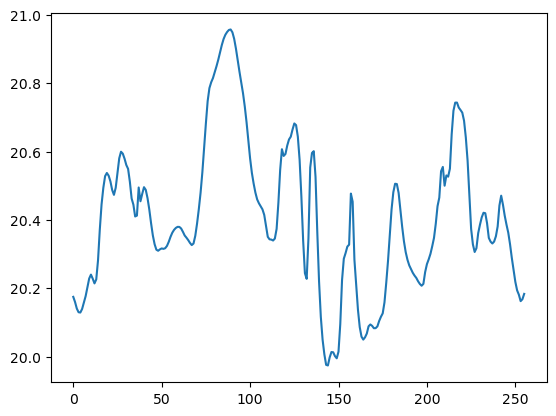

In [3]:
im = np.load(DATA_TEST_PATH + "/" + 'Turb_6.npy')[:,None,:,:]
data = DataClass(im[0,0,0], pbc=True)
plt.plot(data.array.cpu().numpy())

In [4]:
wavelet_op = data.get_wavelet_op()
mean = wavelet_op.mean(data=data)
print("Mean of stl_data_type:", mean)

Mean of stl_data_type: tensor(20.4088, device='mps:0')


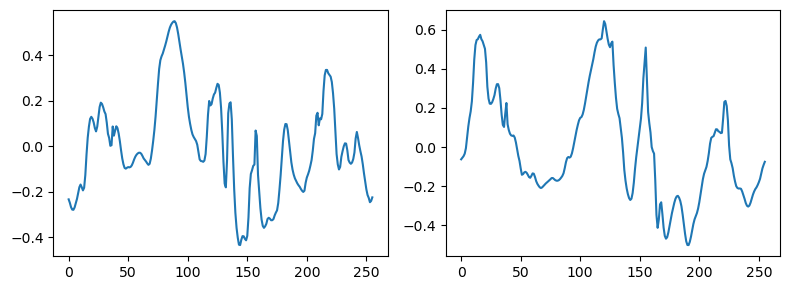

Covariance = tensor(0.0176, device='mps:0')



In [5]:
# Prepare centralized data for covariance tests
stl_data0 = DataClass(im[0,0,0]-im[0,0,0].mean())
stl_data1 = DataClass(im[1,0,0]-im[1,0,0].mean())

# Plot
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes = axes.ravel()
axes[0].plot(stl_data0.array.cpu().numpy())
axes[1].plot(stl_data1.array.cpu().numpy())
plt.tight_layout()
plt.show()

# Test of Cov
cov = wavelet_op.cov(stl_data0, stl_data1)
print("Covariance = " + str(cov))
print()

# test wavelet computation

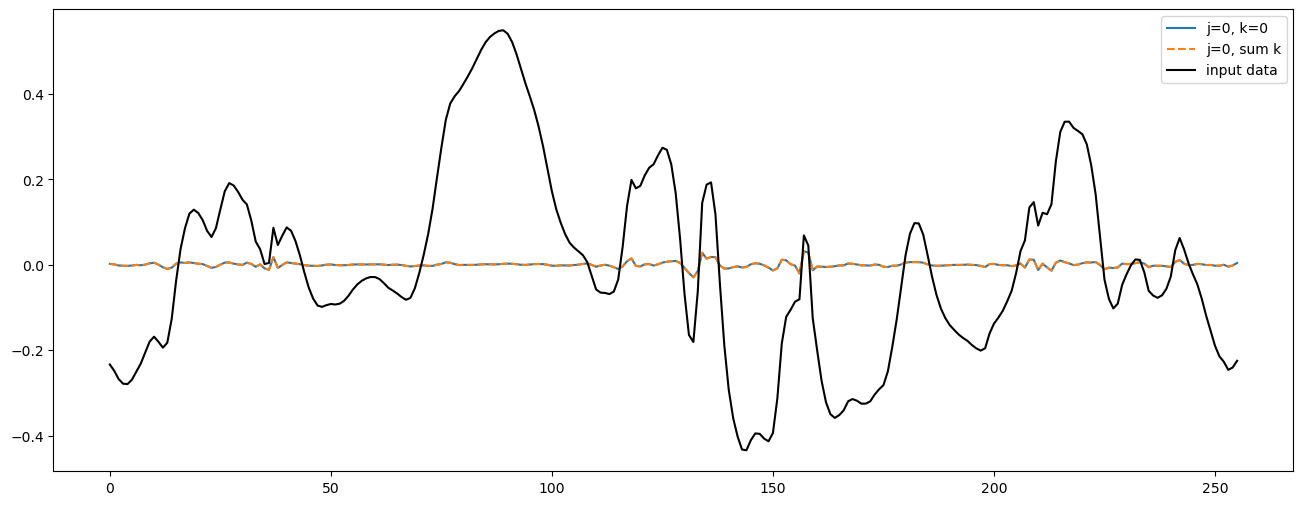

In [6]:
w_op = data.get_wavelet_op(WType="Bump-Steerable")

w_data = w_op.apply(data, j=0)

plt.figure(figsize=(16,6))
for k in range(w_op.L):
    plt.subplot(1,1,1+k)
    plt.plot(w_data.array[k].cpu().numpy().real, label="j=0, k="+str(k))
    plt.plot(w_data.array.sum(axis=0).cpu().numpy().real, label="j=0, sum k", ls='--')
    plt.plot(data.array.cpu().numpy() - data.array.mean().cpu().numpy(), label="input data", c='black')
    plt.legend()

0 6
1 6
2 6
3 6
4 6
5 6


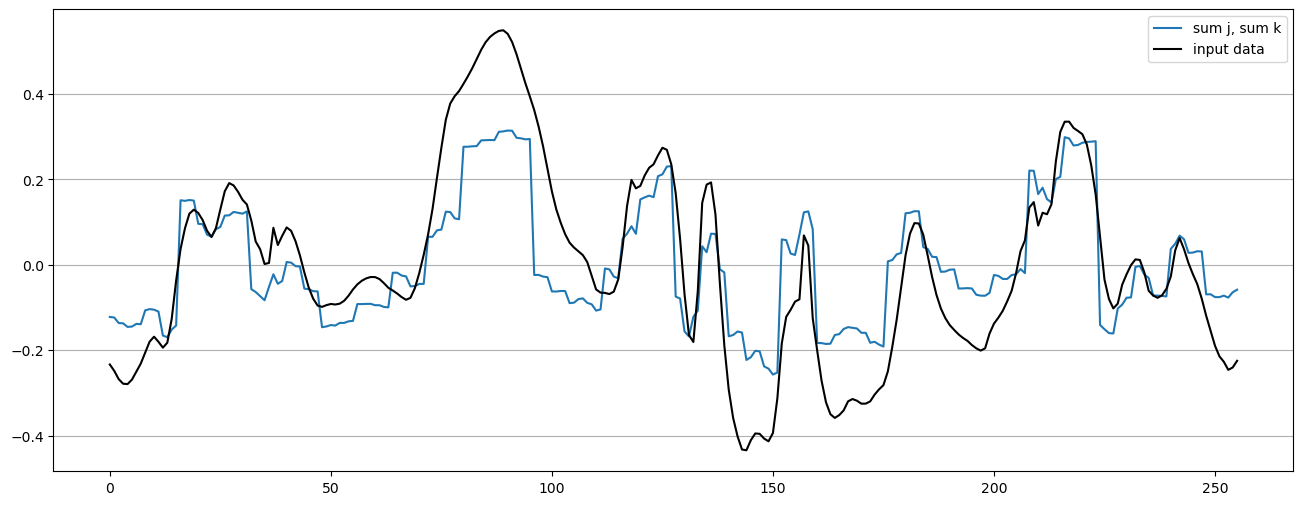

In [7]:
w_op = data.get_wavelet_op(WType="Bump-Steerable")
w_sum = np.zeros_like(data.array.cpu().numpy())

l_data = data.copy()

plt.figure(figsize=(16,6))
for j in range(w_op.J):
    print(j, w_op.J)
    w_data = w_op.apply(l_data, j=j).array.sum(axis=0).cpu().numpy().real
    # oversample w_data by a factor of 2^j
    w_data = np.repeat(w_data, 2**j, axis=0)
    w_sum += w_data
    w_op.downsample(l_data, dg_out=j+1, inplace=True) if j < w_op.J-1 else None

plt.plot(w_sum - w_sum.mean(), label="sum j, sum k")
plt.plot(data.array.cpu().numpy() - data.array.mean().cpu().numpy(), label="input data", c='black')
plt.legend()
plt.grid(True, axis='y')
plt.show()

tensor(20.5145, device='mps:0')


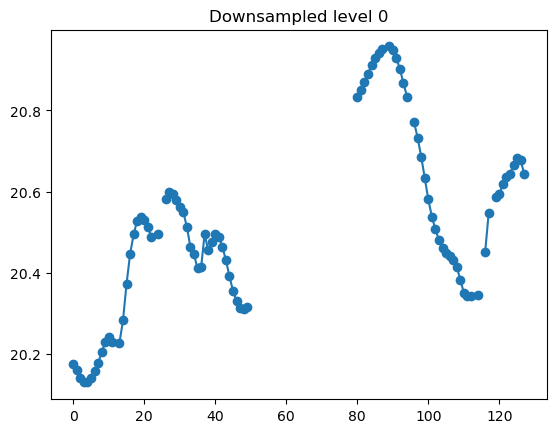

tensor(20.5203, device='mps:0')


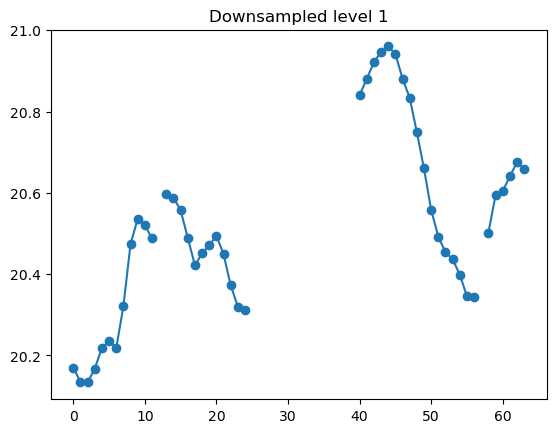

tensor(20.5140, device='mps:0')


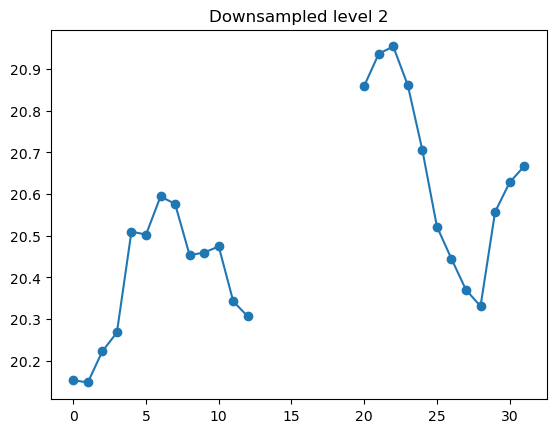

tensor(20.5055, device='mps:0')


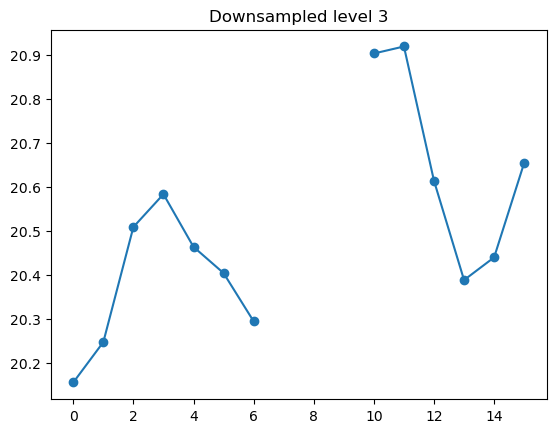

tensor(20.4893, device='mps:0')


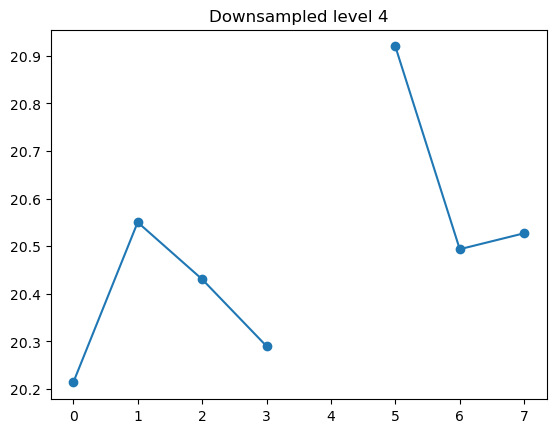

In [8]:
tmp = im[0,0,0].copy()
np.random.seed(32)
tmp[(np.random.rand(25)*tmp.shape[0]).astype('int')] = np.nan
tmp[50:80] = np.nan

l_data = DataClass(tmp[:128], pbc=True)
w_op = l_data.get_wavelet_op(downsample_nan_weight_threshold=0.5)

for dg in range(5):
    print(torch.nanmean(w_op.downsample(l_data, dg_out=dg, inplace=False).array))
    plt.plot(w_op.downsample(l_data, dg_out=dg, inplace=False).array.cpu(), marker='o')
    plt.title("Downsampled level "+str(dg))
    plt.show()

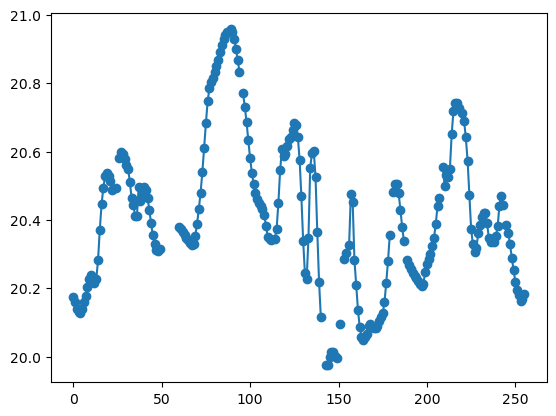

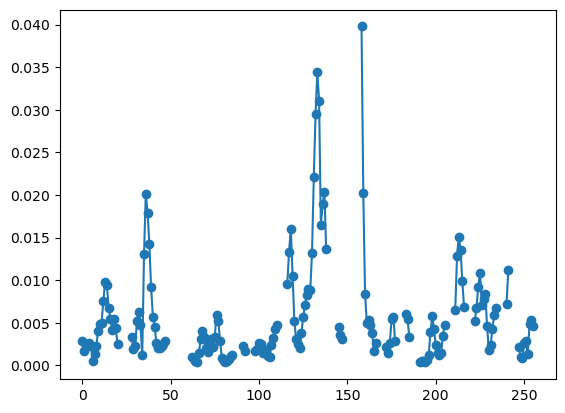

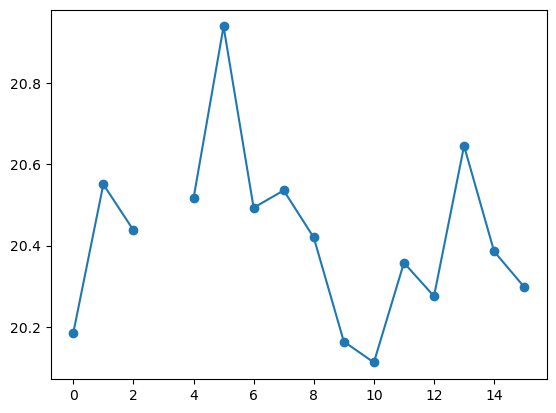

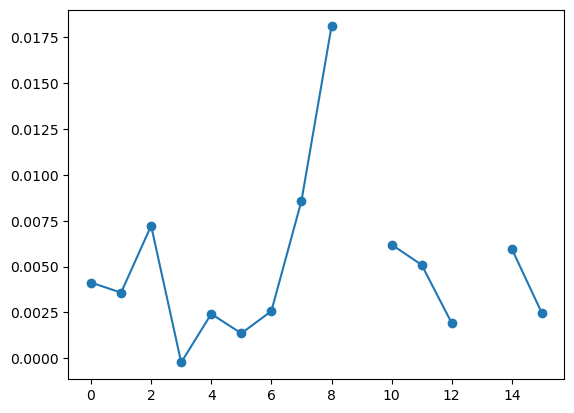

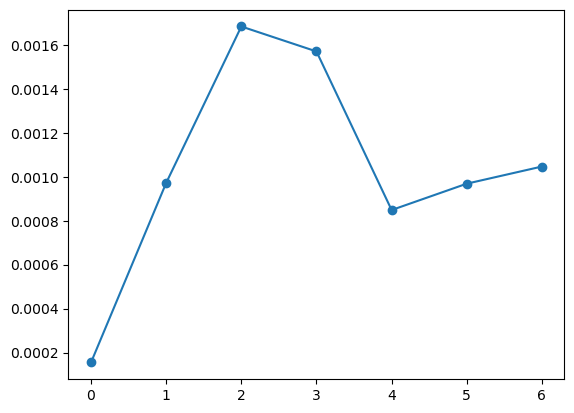

In [9]:
tmp = im[0,0,0].copy()
np.random.seed(32)
tmp[(np.random.rand(17)*tmp.shape[0]).astype('int')] = np.nan
tmp[50:60] = np.nan

plt.plot(tmp, marker='o'), plt.show()

l_data = DataClass(tmp, pbc=True)
w_op = l_data.get_wavelet_op(downsample_nan_weight_threshold=0.5)

w_data = w_op.apply(l_data, j=0)
plt.plot(w_data[0].modulus(inplace=False).array.cpu().numpy(), marker='o'), plt.show()


j = 4

plt.plot(w_op.downsample(l_data, dg_out=j, inplace=False).modulus(inplace=False).array.cpu().numpy(), marker='o'), plt.show()


w_data = w_op.downsample(w_data.modulus(inplace=False), dg_out=j, inplace=True)
plt.plot(w_data[0].array.cpu().numpy(), marker='o'), plt.show()

w_data = w_op.apply(w_data, j=j)
plt.plot(w_data[0,0].modulus().array.cpu().numpy(), marker='o')
plt.show()

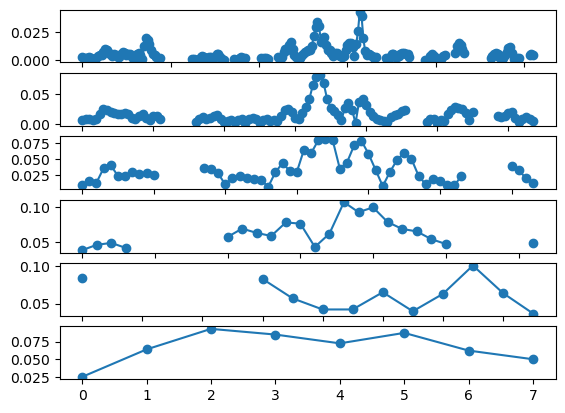

In [10]:
tmp = im[0,0,0].copy()
np.random.seed(27)
tmp[(np.random.rand(17)*tmp.shape[0]).astype('int')] = np.nan
tmp[50:60] = np.nan

l_data = DataClass(tmp, pbc=True)
w_op = l_data.get_wavelet_op(downsample_nan_weight_threshold=0.5)


for j in range(w_op.J):
    w_data = w_op.apply(l_data, j=j)
    for k in range(w_op.L):
        plt.subplot(w_op.J,w_op.L,1+k+w_op.L*j)
        plt.plot(w_data[k].modulus().array.cpu().numpy(), marker='o')
        
    w_op.downsample(l_data, dg_out=j+1, inplace=True) if j < w_op.J-1 else None

In [11]:
l_data = DataClass(im[0,0,0], pbc=True)
l_data_nan = DataClass(tmp, pbc=True)

st_op = l_data.get_ST_op()
st_op_nan = l_data_nan.get_ST_op(downsample_nan_weight_threshold=0.33, 
                                 replace_nan_value=torch.nan)

st_data_nan = st_op_nan.apply(l_data_nan, compute_PS=False)
st_data = st_op.apply(l_data)

/Users/richard/miniconda3/envs/gpu310/lib/python3.10/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/richard/miniconda3/envs/gpu310/lib/python3.10/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


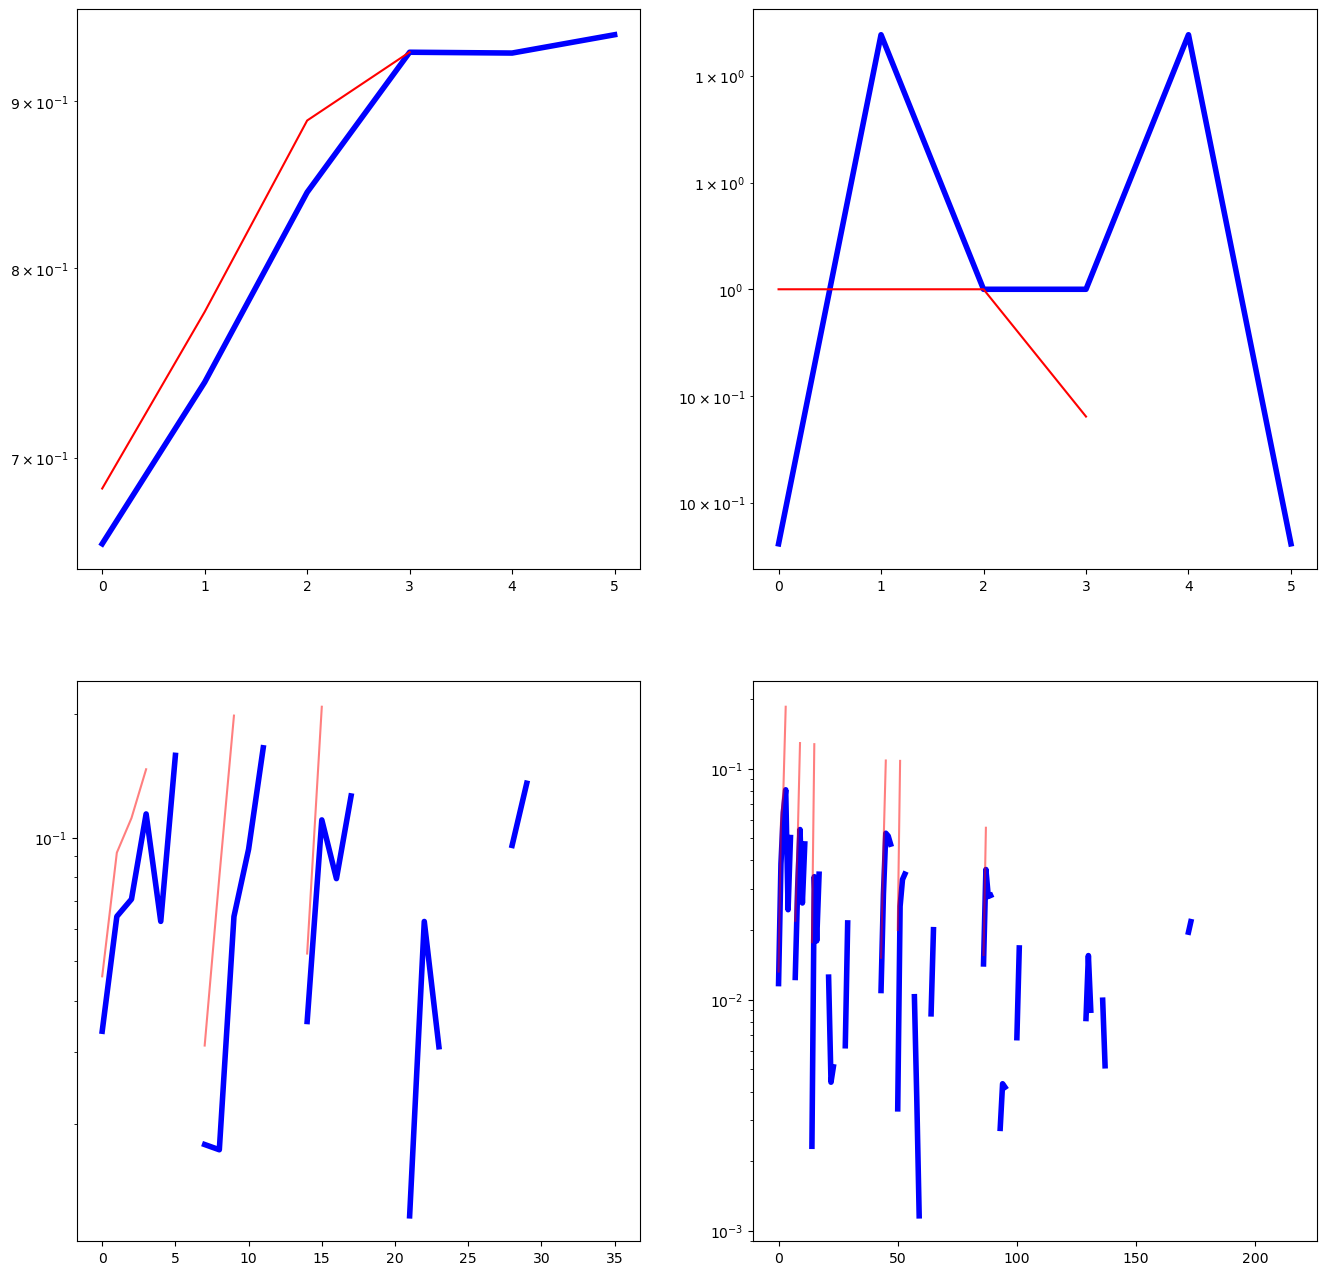

In [12]:
plt.figure(figsize=(16,16))
plt.subplot(2,2,1)
plt.plot(st_data.S1.cpu().numpy().flatten(),color='b',lw=4)
plt.plot(st_data_nan.S1.cpu().numpy().flatten(),color='r')
plt.yscale('log')
plt.subplot(2,2,2)
plt.plot(st_data.S2.cpu().numpy().flatten(),color='b',lw=4)
plt.plot(st_data_nan.S2.cpu().numpy().flatten(),color='r')
plt.yscale('log')


plt.subplot(2,2,3)
plt.plot(st_data.S3.abs().cpu().numpy().flatten(),color='b',lw=4)
plt.plot(st_data_nan.S3.abs().cpu().numpy().flatten(),color='r', alpha=0.5)
plt.yscale('log')
plt.subplot(2,2,4)
plt.plot(st_data.S4.cpu().abs().numpy().flatten(),color='b',lw=4)
plt.plot(st_data_nan.S4.cpu().abs().numpy().flatten(),color='r', alpha=0.5)
plt.yscale('log')

# normalization

In [13]:
st_data = st_op.apply(l_data)
st_data_norm = st_op.apply(l_data, norm='store_ref')

Replacing existing var_ref in ST_Op
Replacing existing S2_ref_sqrt_chan_diag in ST_Op
Replacing existing PS_ref_sqrt_chan_diag in ST_Op
Replacing existing var_ref in ST_Op
Replacing existing S2_ref_sqrt_chan_diag in ST_Op
Replacing existing PS_ref_sqrt_chan_diag in ST_Op


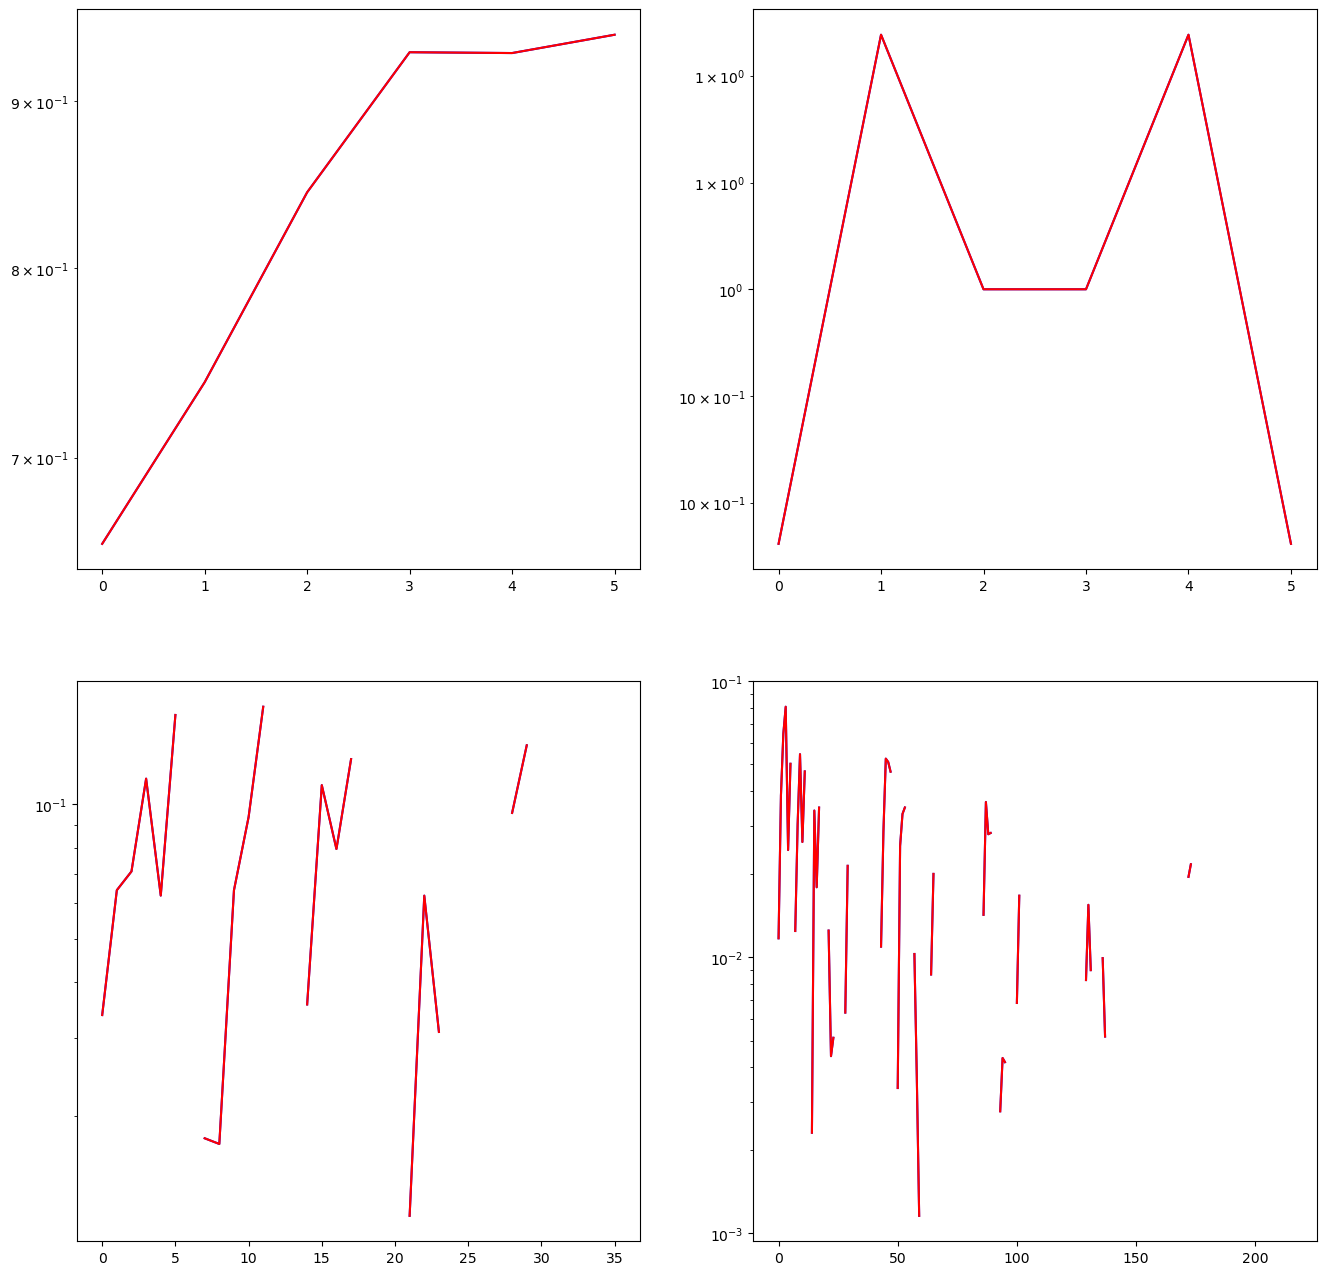

In [14]:
plt.figure(figsize=(16,16))
plt.subplot(2,2,1)
plt.plot(st_data.S1.cpu().numpy().flatten(),color='b')
plt.plot(st_data_norm.S1.cpu().numpy().flatten(),color='r')
plt.yscale('log')
plt.subplot(2,2,2)
plt.plot(st_data.S2.cpu().numpy().flatten(),color='b')
plt.plot(st_data_norm.S2.cpu().numpy().flatten(),color='r')
plt.yscale('log')

plt.subplot(2,2,3)
plt.plot(st_data.S3.abs().cpu().numpy().flatten(),color='b')
plt.plot(st_data_norm.S3.abs().cpu().numpy().flatten(),color='r')
plt.yscale('log')
plt.subplot(2,2,4)
plt.plot(st_data.S4.cpu().abs().numpy().flatten(),color='b')
plt.plot(st_data_norm.S4.cpu().abs().numpy().flatten(),color='r')
plt.yscale('log')

# PBC = False

Warning! Data with shape (8,) too small to be cropped with border 4. Using border=3 instead.


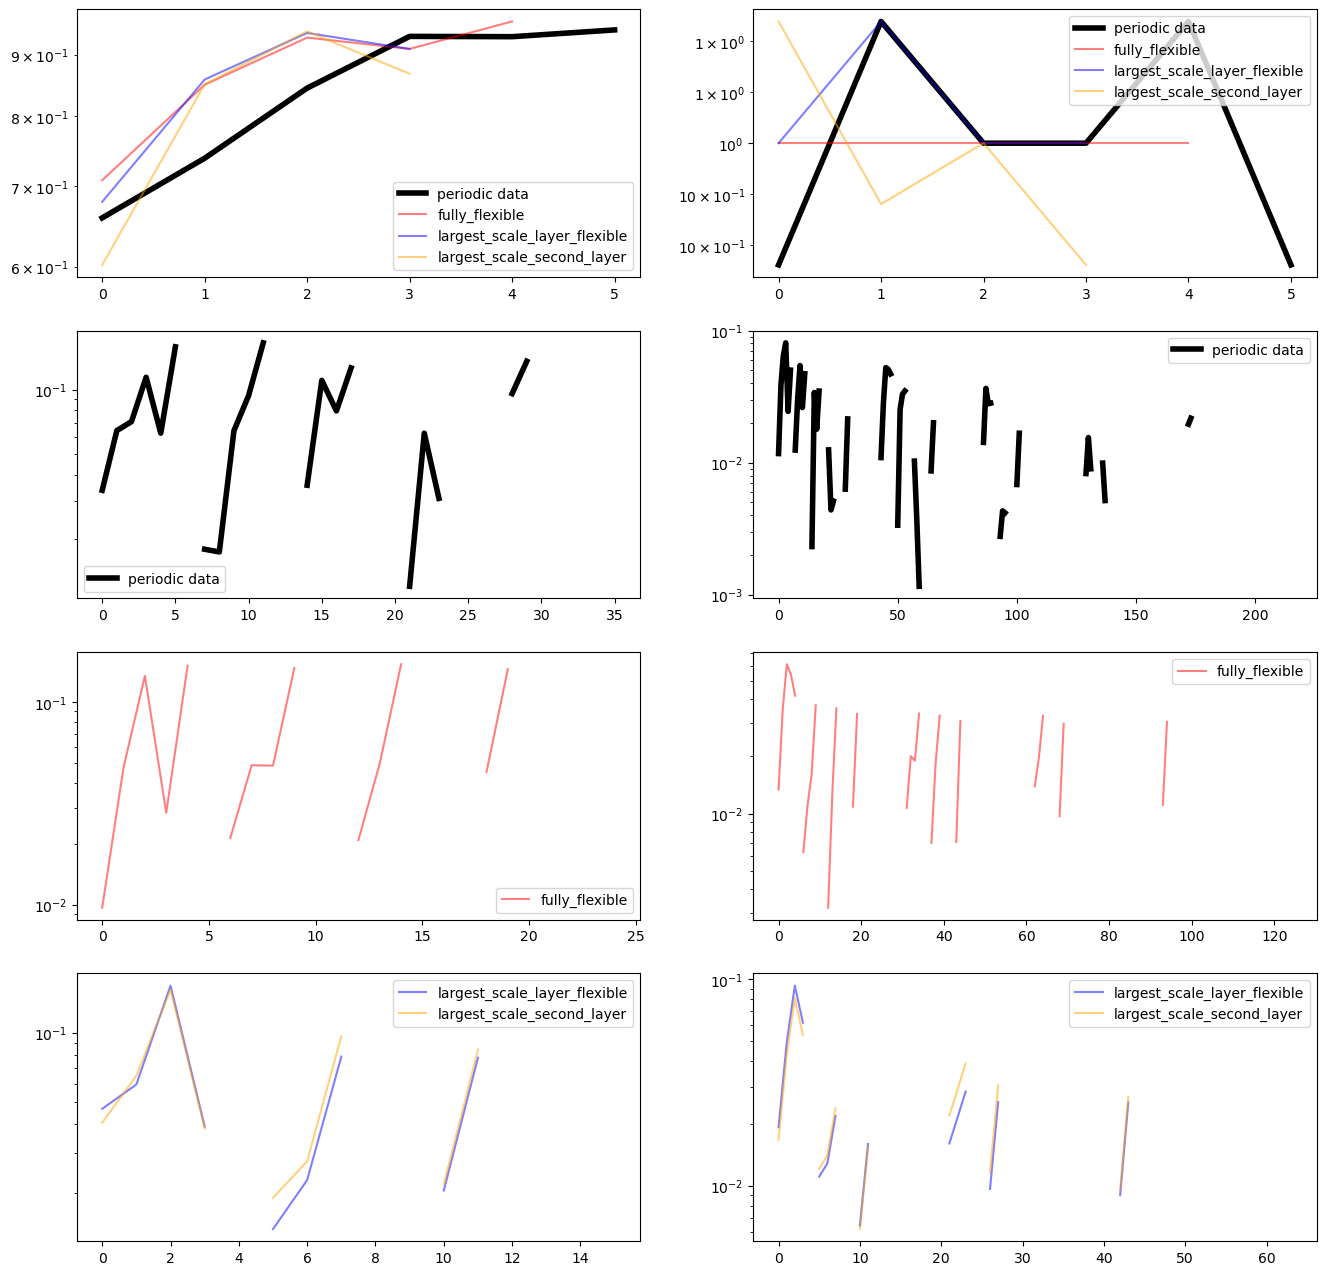

In [15]:
from STL_main.STL_2D_Kernel_Torch import WaveletOperator2Dkernel_torch as WO

l_data = DataClass(im[0,0,0], pbc=True)
l_data_npbc = DataClass(im[0,0,0,:128], pbc=False)

st_op = l_data.get_ST_op()
st_data = st_op.apply(l_data)

plt.figure(figsize=(16,16))

plt.subplot(4,2,1)
plt.plot(st_data.S1.cpu().numpy().flatten(), color='black', lw=4, label='periodic data')

plt.subplot(4,2,2)
plt.plot(st_data.S2.cpu().numpy().flatten(), color='black', lw=4, label='periodic data')

plt.subplot(4,2,3)
plt.plot(st_data.S3.abs().cpu().numpy().flatten(), color='black', lw=4, label='periodic data')
plt.yscale('log')
plt.legend()

plt.subplot(4,2,4)
plt.plot(st_data.S4.cpu().abs().numpy().flatten(), color='black', lw=4, label='periodic data')
plt.yscale('log')
plt.legend()

colors = {'fully_flexible': 'r',
          'largest_scale_layer_flexible': 'blue',
          'largest_scale_second_layer': 'orange'}

for method_name, get_crop_border_size_method in zip(['fully_flexible', 
                                                     'largest_scale_layer_flexible', 
                                                     'largest_scale_second_layer'],
                                                    [WO._get_crop_border_size_fully_flexible,
                                                     WO._get_crop_border_size_largest_scale_layer_flexible,
                                                     WO._get_crop_border_size_largest_scale_second_layer]):
    
    st_op_npbc = l_data_npbc.get_ST_op(
        J=5 if method_name == 'fully_flexible' else 4,
        get_crop_border_size_method=get_crop_border_size_method)
    st_data_npbc = st_op_npbc.apply(l_data_npbc)

    plt.subplot(4,2,1)
    plt.plot(st_data_npbc.S1.cpu().numpy().flatten(),color=colors[method_name], label=method_name, alpha=0.5)
    plt.yscale('log')
    plt.legend()

    plt.subplot(4,2,2)
    plt.plot(st_data_npbc.S2.cpu().numpy().flatten(),color=colors[method_name], label=method_name, alpha=0.5)
    plt.yscale('log')
    plt.legend()

    plt.subplot(4,2,7 if method_name != 'fully_flexible' else 5)
    plt.plot(st_data_npbc.S3.abs().cpu().numpy().flatten(),color=colors[method_name], label=method_name, alpha=0.5)
    plt.yscale('log')
    plt.legend()

    plt.subplot(4,2,8 if method_name != 'fully_flexible' else 6)
    plt.plot(st_data_npbc.S4.cpu().abs().numpy().flatten(),color=colors[method_name], label=method_name, alpha=0.5)
    plt.yscale('log')
    plt.legend()

plt.show()

# simple synthesis

In [16]:
seed = 42

def plot_synthesized_and_target(u, target):

    if u.ndim == 3:
        chan = True
        assert u.shape[1] == 2, "Only 2 channels are supported for plotting"
    else:
        chan = False

    plt.figure(figsize=(10,10))
    plt.subplot(2,2,1)
    if chan:
        plt.axhline(0, color='black', lw=1)
        plt.plot(u[0,0].cpu().numpy(), label='Channel 1')
        plt.plot(u[0,1].cpu().numpy(), label='Channel 2')
        plt.legend()
    else:
        plt.plot(u[0].cpu().numpy())
    plt.axis('off')
    plt.title('Synthetised #0')

    plt.subplot(2,2,2)
    if chan:
        plt.axhline(0, color='black', lw=1)
        plt.plot(target[0], label='Channel 1')
        plt.plot(target[1], label='Channel 2')
        plt.legend()
    else:
        plt.plot(target)
    plt.axis('off')
    plt.title('Target')

    fft1 = np.abs(np.fft.fftshift(np.fft.fft(u[0].cpu().numpy(), axis=-1), axes=-1))
    fft2 = np.abs(np.fft.fftshift(np.fft.fft(target, axis=-1), axes=-1))

    q = 1e-2
    vmax = max(np.nanquantile(fft1, 1-q), np.nanquantile(fft2, 1-q))
    vmin = min(np.nanquantile(fft1, q),   np.nanquantile(fft2, q))

    if np.isfinite(vmax):
        plt.figure(figsize=(10,10))
        plt.subplot(2,2,1)

        if np.isfinite(np.nanquantile(fft1, 1-q)):
            if chan:
                plt.plot(fft1[0], label='Channel 1')
                plt.plot(fft1[1], label='Channel 2')
                plt.legend()
            else:
                plt.plot(fft1)
        plt.yscale('log')
        plt.ylim(plt.gca().get_ylim())
        plt.title('FFT Synthetised #0 Fourier')

        plt.subplot(2,2,2, sharey=plt.gca())
        if np.isfinite(np.nanquantile(fft2, 1-q)):
            if chan:
                plt.plot(fft2[0], label='Channel 1')
                plt.plot(fft2[1], label='Channel 2')
                plt.legend()
            else:
                plt.plot(fft2)
        # share the y-axis with the first subplot
        plt.yscale('log')
        plt.title('Target Fourier')
        plt.show()

    plt.figure(figsize=(16,4))
    for k in range(4):
        plt.subplot(1,4,1+k)
        if chan:
            plt.axhline(0, color='black', lw=1)
            plt.plot(u[k,0].cpu().numpy(), label='Channel 1')
            plt.plot(u[k,1].cpu().numpy(), label='Channel 2')
            plt.legend()
        else:
            plt.plot(u[k].cpu().numpy())
        plt.axis('off')
        plt.title('Synthetised #%d'%(k))

In [17]:
u0 = synthesize_from_maps(
    DataClass(im[0,0,0], pbc=True),
    pbc_running=True,
    nbatch=4,
    max_iter=300,
    seed=seed,
)

Running synthesis on device: mps:0 dtype: torch.float32
Initial shape for u: (4, 1, 256)
Prefiltering target to remove frequencies above Nyquist
Synthesis on 107 ST coefficients
Prefiltering initial map to remove frequencies above Nyquist
[LBFGS] iter 10, loss = 1.038091e+03
[LBFGS] iter 20, loss = 9.286250e+00
[LBFGS] iter 30, loss = 3.690715e+00
[LBFGS] iter 40, loss = 1.066423e+00
[LBFGS] iter 50, loss = 6.650345e-01
[LBFGS] iter 60, loss = 5.431572e-01
[LBFGS] iter 70, loss = 4.561751e-01
[LBFGS] iter 80, loss = 3.815692e-01
[LBFGS] iter 90, loss = 3.112392e-01
[LBFGS] iter 100, loss = 2.434465e-01
[LBFGS] iter 110, loss = 1.937987e-01
[LBFGS] iter 120, loss = 1.504679e-01
[LBFGS] iter 130, loss = 9.932145e-02
[LBFGS] iter 140, loss = 7.515471e-02
[LBFGS] iter 150, loss = 5.858706e-02
[LBFGS] iter 160, loss = 4.660009e-02
[LBFGS] iter 170, loss = 3.919092e-02
[LBFGS] iter 180, loss = 3.211736e-02
[LBFGS] iter 190, loss = 2.769563e-02
[LBFGS] iter 200, loss = 2.334724e-02
[LBFGS] it

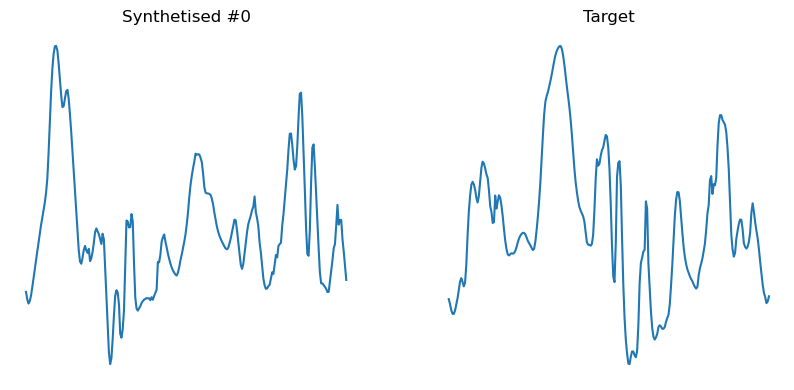

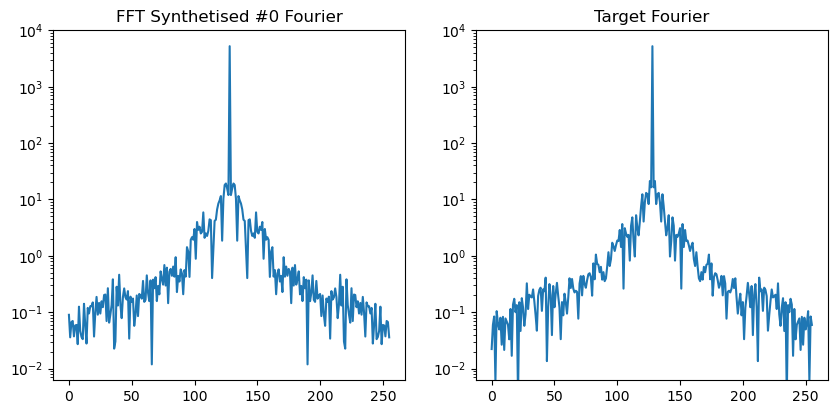

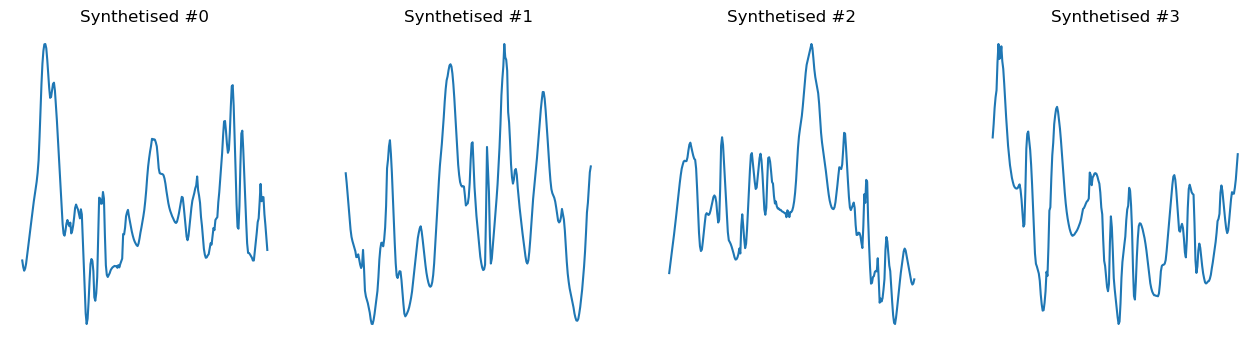

In [18]:
plot_synthesized_and_target(u0[:,:], im[0,0,0])

# multichannel synthesis

In [19]:
target_multi = np.stack([im[0,0,0], (im[0,0,0]-im[0,0,0].mean(keepdims=True))**2])
target_multi -= target_multi.mean(axis=(-1,), keepdims=True)
target_multi = DataClass(target_multi, pbc=True)
st_op = target_multi.get_ST_op()

In [20]:
compute_cross_matrix = torch.tensor([[1, 1], [0, 1]], dtype=torch.bool)
compute_cross_matrix

tensor([[ True,  True],
        [False,  True]])

In [21]:
u1 = synthesize_from_maps(
        data_target=target_multi,
        pbc_running=True,
        compute_cross_matrix=compute_cross_matrix,        
        compute_PS=False,
        nbatch=4,
        max_iter=400,
        seed=seed,
    )

Running synthesis on device: mps:0 dtype: torch.float32
Initial shape for u: (4, 2, 256)
Prefiltering target to remove frequencies above Nyquist
Synthesis on 348 ST coefficients
Prefiltering initial map to remove frequencies above Nyquist
[LBFGS] iter 10, loss = 1.291233e+02
[LBFGS] iter 20, loss = 1.783759e+01
[LBFGS] iter 30, loss = 7.070951e+00
[LBFGS] iter 40, loss = 3.050032e+00
[LBFGS] iter 50, loss = 1.938377e+00
[LBFGS] iter 60, loss = 1.332806e+00
[LBFGS] iter 70, loss = 9.457989e-01
[LBFGS] iter 80, loss = 7.620926e-01
[LBFGS] iter 90, loss = 5.969318e-01
[LBFGS] iter 100, loss = 4.397582e-01
[LBFGS] iter 110, loss = 3.380145e-01
[LBFGS] iter 120, loss = 2.644884e-01
[LBFGS] iter 130, loss = 2.010865e-01
[LBFGS] iter 140, loss = 1.641378e-01
[LBFGS] iter 150, loss = 1.350729e-01
[LBFGS] iter 160, loss = 1.100161e-01
[LBFGS] iter 170, loss = 9.299859e-02
[LBFGS] iter 180, loss = 7.961208e-02
[LBFGS] iter 190, loss = 6.869631e-02
[LBFGS] iter 200, loss = 6.042273e-02
[LBFGS] it

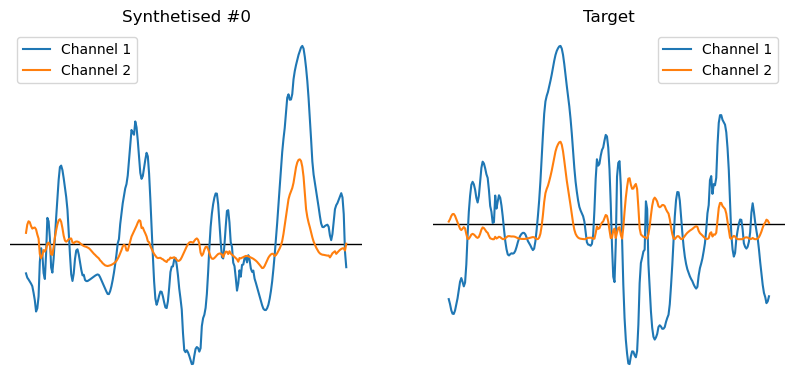

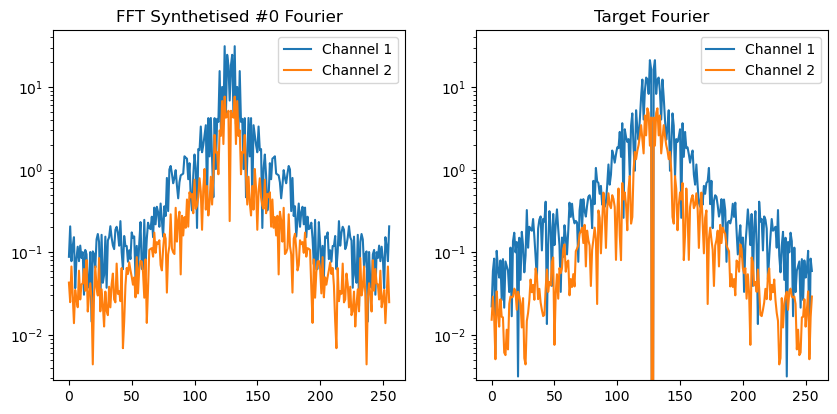

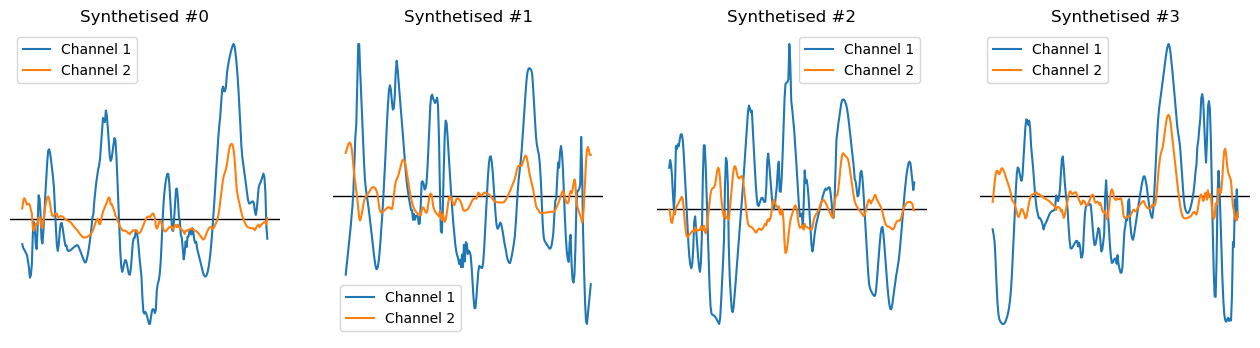

In [23]:
plot_synthesized_and_target(u1[:,:], target_multi.array.cpu().numpy())

# Synthesis with NaNs

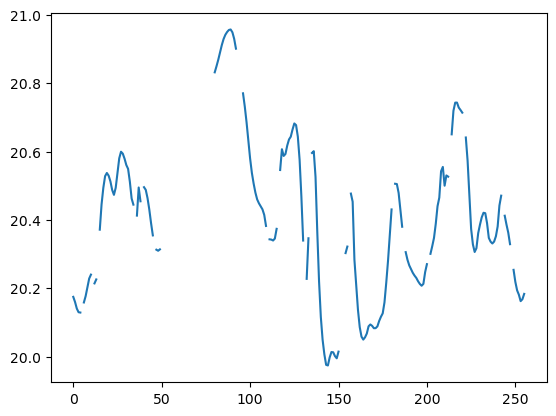

In [24]:
tmp = im[0,0,0].copy()
np.random.seed(seed)
tmp[(np.random.rand(30)*tmp.shape[0]).astype('int')] = np.nan
tmp[50:80] = np.nan
plt.plot(tmp)
plt.show()

## Running without NaNs

In [25]:
target = DataClass(tmp, pbc=True)

u2 = synthesize_from_maps(
        data_target=target,
        pbc_running=True,
        running_mask=np.zeros_like(target.array.cpu().numpy()),
        nbatch=4,
        max_iter=300,
        seed=seed,
    )

⚠️ Warning: NaN detected in target and/or running data.
Power spectrum optimization is disabled because its computation is not yet implemented for NaN values in any dataclass. 

Running synthesis on device: mps:0 dtype: torch.float32
NaN detected in the target, the synthesis takes it into account
Initial shape for u: (4, 1, 256)
Synthesis on 91 ST coefficients
Prefiltering initial map to remove frequencies above Nyquist
[LBFGS] iter 10, loss = 2.420315e+02
[LBFGS] iter 20, loss = 2.262502e+01
[LBFGS] iter 30, loss = 1.819204e+01
[LBFGS] iter 40, loss = 1.553223e+01
[LBFGS] iter 50, loss = 1.308590e+01
[LBFGS] iter 60, loss = 1.164022e+01
[LBFGS] iter 70, loss = 1.084145e+01
[LBFGS] iter 80, loss = 1.020879e+01
[LBFGS] iter 90, loss = 9.708490e+00
[LBFGS] iter 100, loss = 9.392342e+00
[LBFGS] iter 110, loss = 9.132315e+00
[LBFGS] iter 120, loss = 8.834145e+00
[LBFGS] iter 130, loss = 8.644464e+00
[LBFGS] iter 140, loss = 8.461762e+00
[LBFGS] iter 150, loss = 8.259443e+00
[LBFGS] iter 16

/Users/richard/miniconda3/envs/gpu310/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:1601: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


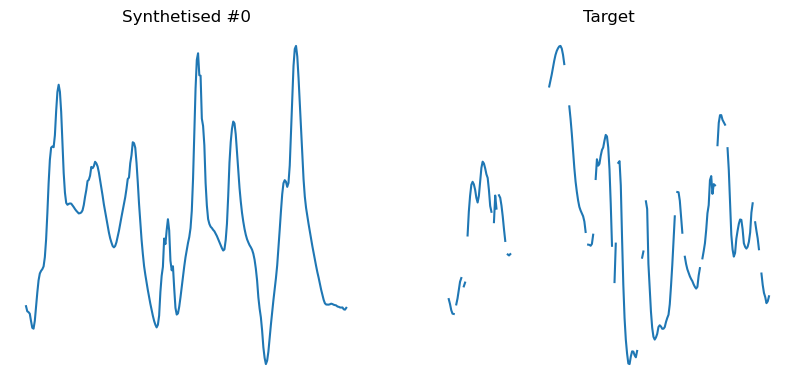

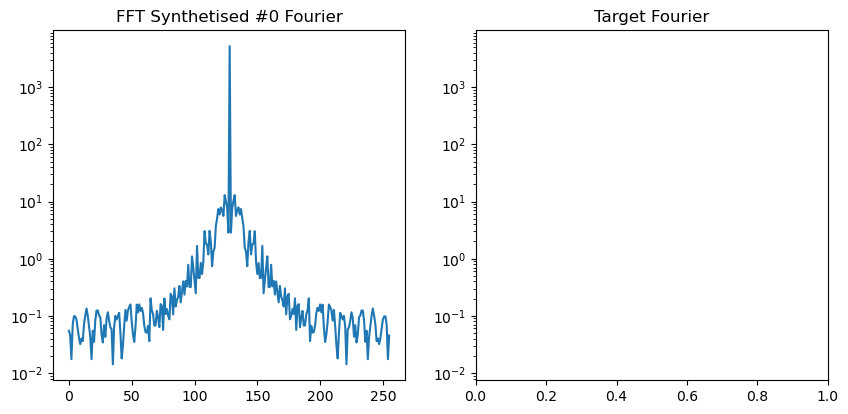

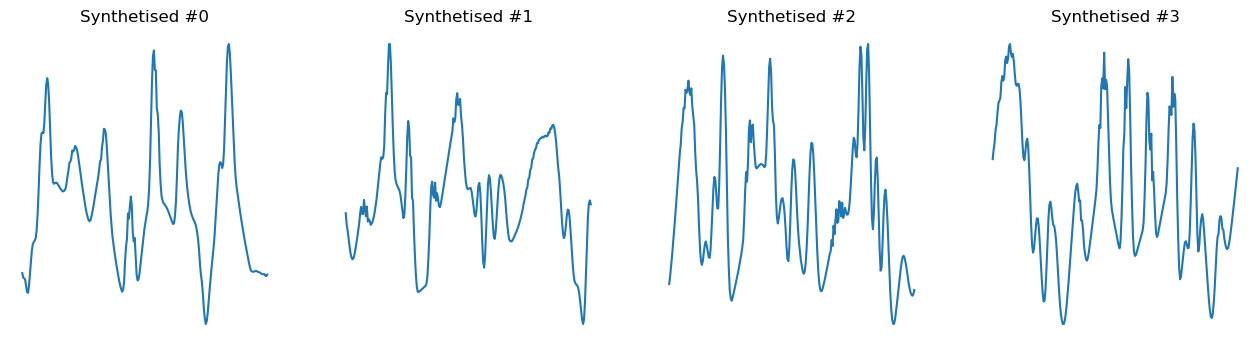

In [26]:
plot_synthesized_and_target(u2, target.array.cpu().numpy())

## Running with same NaN mask as target

In [27]:
u3 = synthesize_from_maps(
        data_target=target,
        pbc_running=True,
        nbatch=4,
        max_iter=300,
        seed=seed,
    )

⚠️ Warning: NaN detected in target and/or running data.
Power spectrum optimization is disabled because its computation is not yet implemented for NaN values in any dataclass. 

Running synthesis on device: mps:0 dtype: torch.float32
NaN detected in the target, the synthesis takes it into account
Initial shape for u: (4, 1, 256)
Synthesis on 91 ST coefficients
Prefiltering initial map to remove frequencies above Nyquist
NaN detected in the running synthesis mask, the synthesis takes it into account
[LBFGS] iter 10, loss = 5.038926e+02
[LBFGS] iter 20, loss = 2.472786e+01
[LBFGS] iter 30, loss = 1.416596e+01
[LBFGS] iter 40, loss = 9.137698e+00
[LBFGS] iter 50, loss = 7.388284e+00
[LBFGS] iter 60, loss = 6.453918e+00
[LBFGS] iter 70, loss = 5.370250e+00
[LBFGS] iter 80, loss = 4.432038e+00
[LBFGS] iter 90, loss = 3.501115e+00
[LBFGS] iter 100, loss = 2.793428e+00
[LBFGS] iter 110, loss = 2.392184e+00
[LBFGS] iter 120, loss = 2.044722e+00
[LBFGS] iter 130, loss = 1.829100e+00
[LBFGS] ite

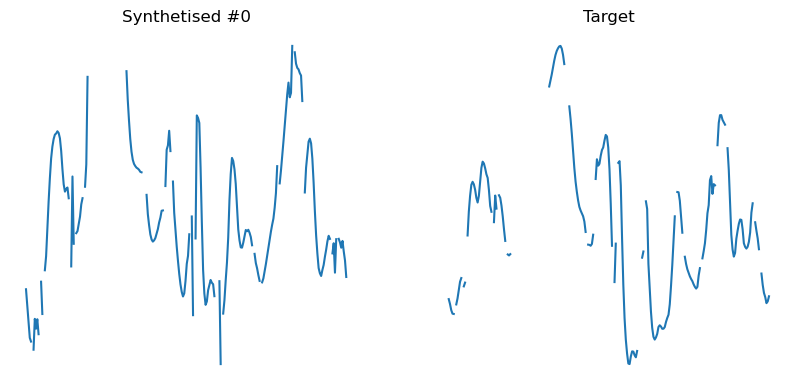

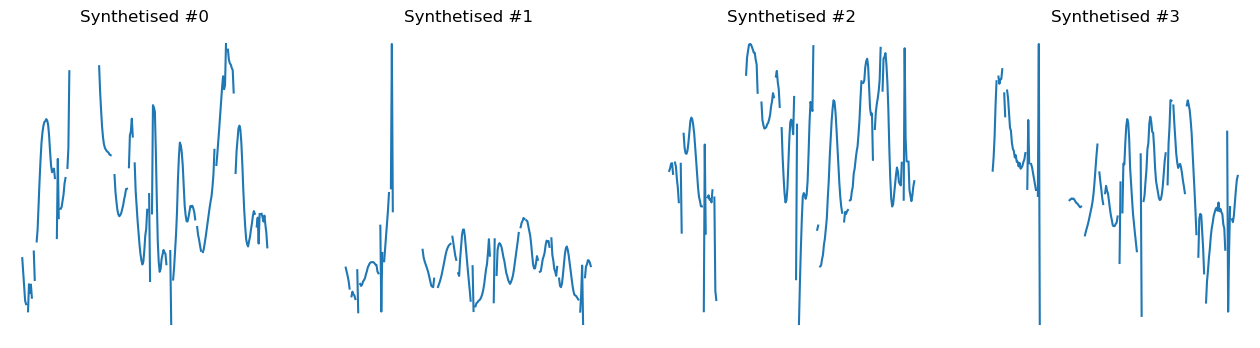

In [28]:
plot_synthesized_and_target(u3, tmp)

## Running with new NaN mask

In [29]:
new_mask = np.zeros_like(im[0,0,0])
new_mask[150:175] = np.nan

In [30]:
u4 = synthesize_from_maps(
        data_target=target,
        pbc_running=True,
        running_mask=new_mask,
        nbatch=4,
        max_iter=300,
        seed=seed,
    )

⚠️ Warning: NaN detected in target and/or running data.
Power spectrum optimization is disabled because its computation is not yet implemented for NaN values in any dataclass. 

Running synthesis on device: mps:0 dtype: torch.float32
NaN detected in the target, the synthesis takes it into account
Initial shape for u: (4, 1, 256)
Synthesis on 91 ST coefficients
Prefiltering initial map to remove frequencies above Nyquist
NaN detected in the running synthesis mask, the synthesis takes it into account


RuntimeError: The size of tensor a (84) must match the size of tensor b (91) at non-singleton dimension 0

In [31]:
plot_synthesized_and_target(u4, tmp)

NameError: name 'u4' is not defined

TypeError: 'NoneType' object is not subscriptable

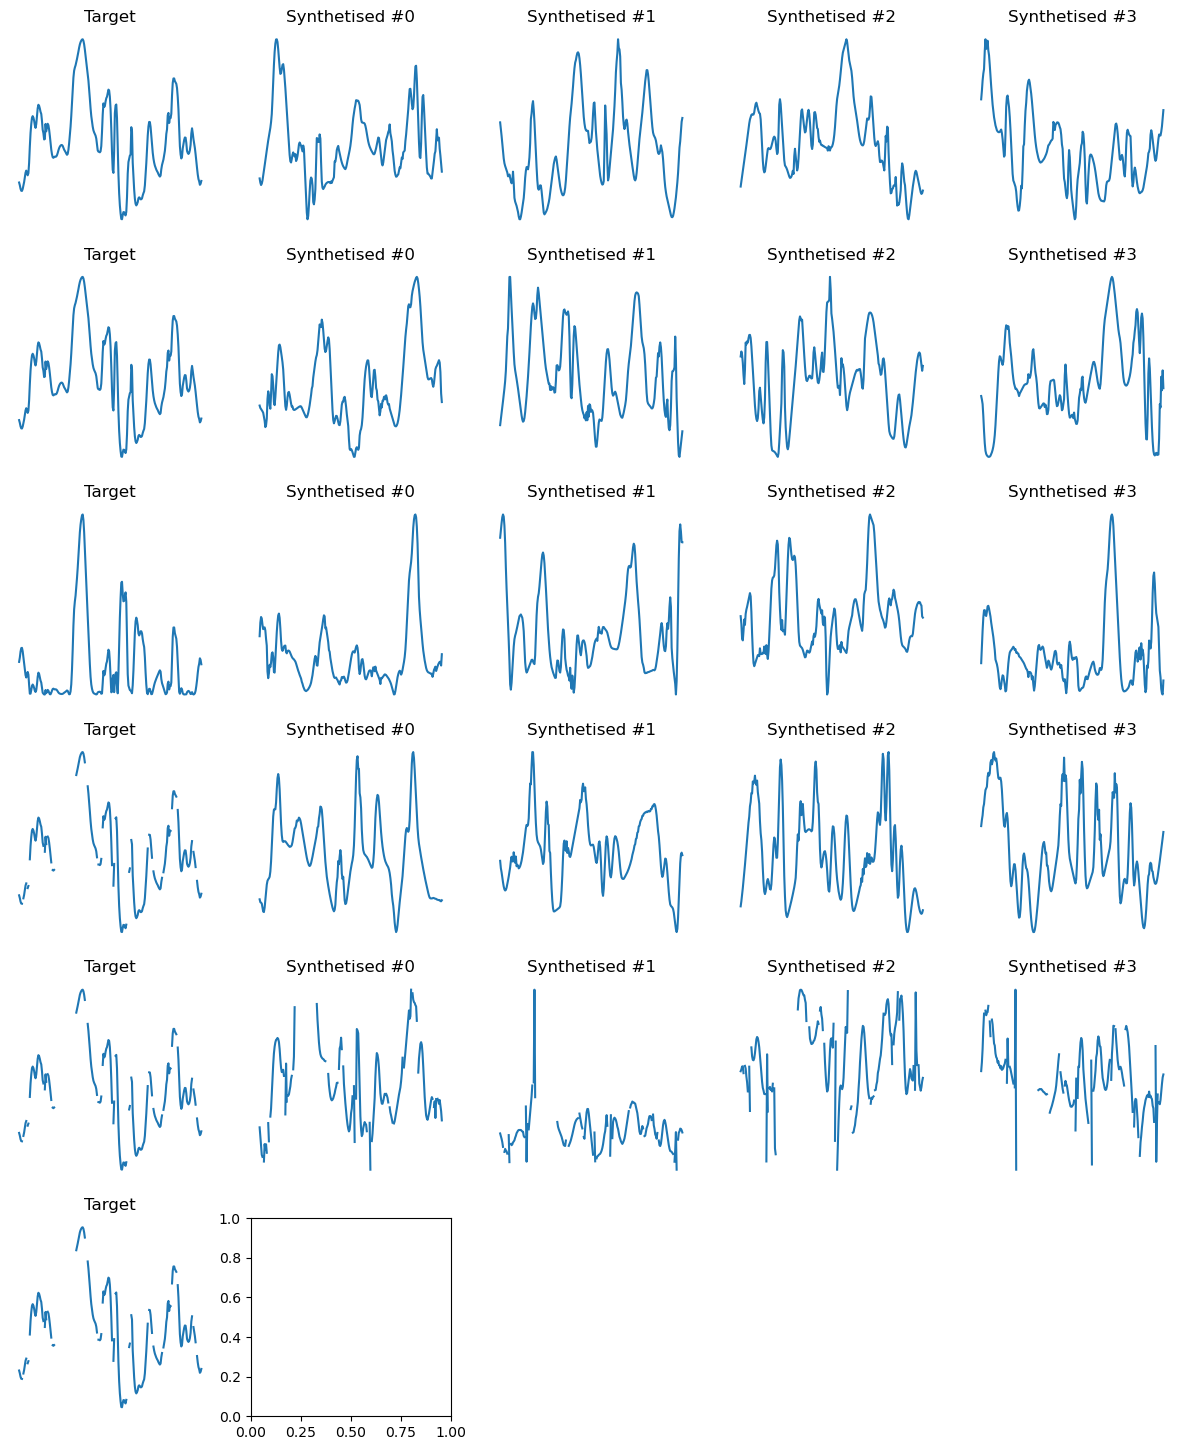

In [33]:
plt.figure(figsize=(5*3, 6*3))
for ind, (u, tgt) in enumerate(zip([u0, u1[:,0], u1[:,1], u2, u3, u4], [im[0,0,0], target_multi.array[0].cpu().numpy(), target_multi.array[1].cpu().numpy(), tmp, tmp, tmp])):
    plt.subplot(6,5,1 + ind*5)
    plt.plot(tgt), plt.axis('off')
    plt.title('Target')
    for k in range(4):
        plt.subplot(6,5,2 + k + ind*5)
        plt.plot(u[k].cpu().numpy())
        plt.title('Synthetised #%d'%(k))
        plt.axis('off')

if False:
    plt.savefig("nan_synthesis.png", bbox_inches='tight', dpi=100)

# synthesis with PBC = False 

In [34]:
synthesis_target_npbc_results = {}

target = DataClass(im[0,0,0,:128], pbc=False)

for method_name, get_crop_border_size_method in zip(['fully_flexible', 
                                                     'largest_scale_layer_flexible', 
                                                     'largest_scale_second_layer'],
                                                    [WO._get_crop_border_size_fully_flexible,
                                                     WO._get_crop_border_size_largest_scale_layer_flexible,
                                                     WO._get_crop_border_size_largest_scale_second_layer]):
    print(method_name)
    J = 5 if method_name == 'fully_flexible' else 4

    u = synthesize_from_maps(
            data_target=target,
            st_op_target_kwargs={"get_crop_border_size_method": get_crop_border_size_method},
            pbc_running=True,
            nbatch=4,
            max_iter=300,
            seed=seed,
        )

    synthesis_target_npbc_results[method_name] = u

fully_flexible
Running synthesis on device: mps:0 dtype: torch.float32
Initial shape for u: (4, 1, 128)
Prefiltering target to remove frequencies above Nyquist
Synthesis on 48 ST coefficients
Prefiltering initial map to remove frequencies above Nyquist
[LBFGS] iter 10, loss = 2.555128e+02
[LBFGS] iter 20, loss = 2.767622e+00
[LBFGS] iter 30, loss = 1.946630e+00
[LBFGS] iter 40, loss = 1.522676e+00
[LBFGS] iter 50, loss = 1.327485e+00
[LBFGS] iter 60, loss = 1.205924e+00
[LBFGS] iter 70, loss = 1.109409e+00
[LBFGS] iter 80, loss = 1.022309e+00
[LBFGS] iter 90, loss = 9.263440e-01
[LBFGS] iter 100, loss = 8.304853e-01
[LBFGS] iter 110, loss = 7.545967e-01
[LBFGS] iter 120, loss = 6.791528e-01
[LBFGS] iter 130, loss = 6.418889e-01
[LBFGS] iter 140, loss = 6.201146e-01
[LBFGS] iter 150, loss = 6.049900e-01
[LBFGS] iter 160, loss = 5.937388e-01
[LBFGS] iter 170, loss = 5.873855e-01
[LBFGS] iter 180, loss = 5.819298e-01
[LBFGS] iter 190, loss = 5.776087e-01
[LBFGS] iter 200, loss = 5.736201e

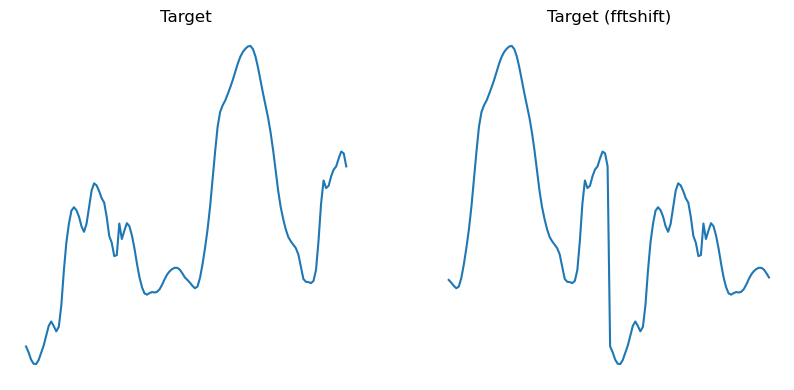

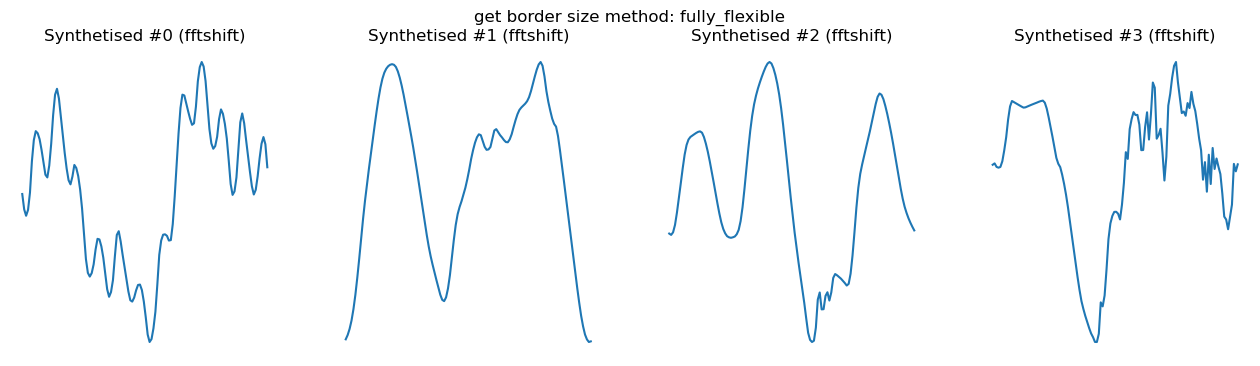

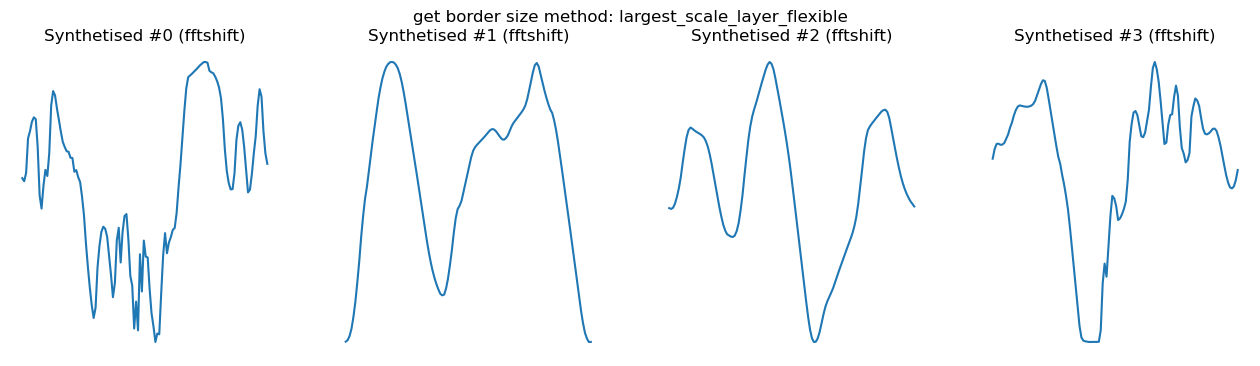

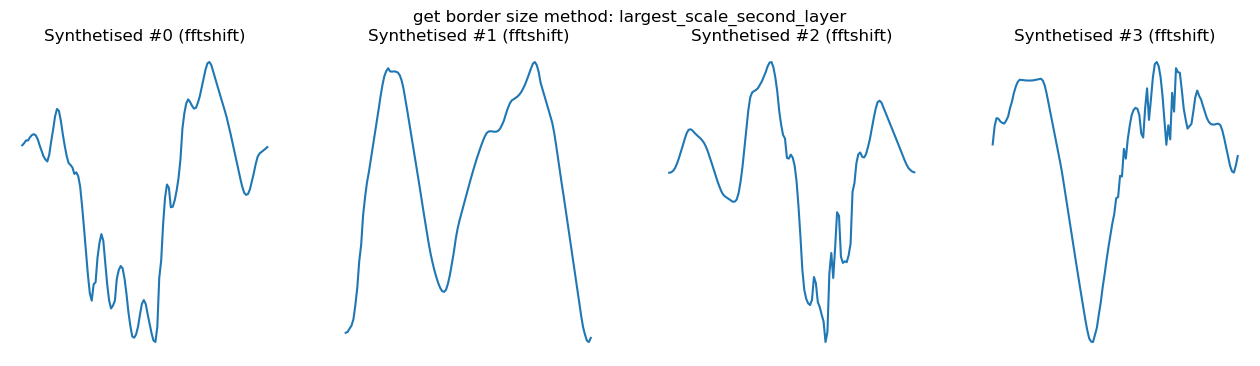

In [35]:
plt.figure(figsize=(10,10))
plt.subplot(2,2,1)
plt.plot(im[0,0,0,:128])
plt.axis('off')
plt.title('Target')
plt.subplot(2,2,2)
plt.plot(np.fft.fftshift(im[0,0,0,:128]))
plt.axis('off')
plt.title('Target (fftshift)')

for method_name, u in synthesis_target_npbc_results.items():

    plt.figure(figsize=(16,4))
    plt.title('get border size method: %s\n'%method_name)
    plt.axis('off')
    for k in range(4):
        plt.subplot(1,4,1+k)
        plt.plot(np.fft.fftshift(u[k].cpu().numpy()))
        plt.axis('off')
        plt.title('Synthetised #%d (fftshift)'%(k))

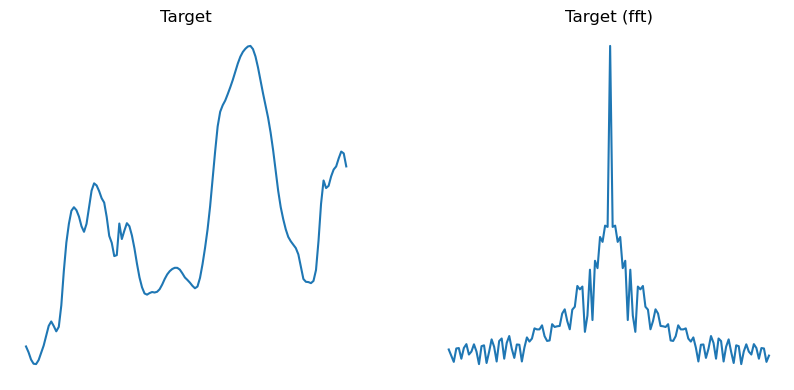

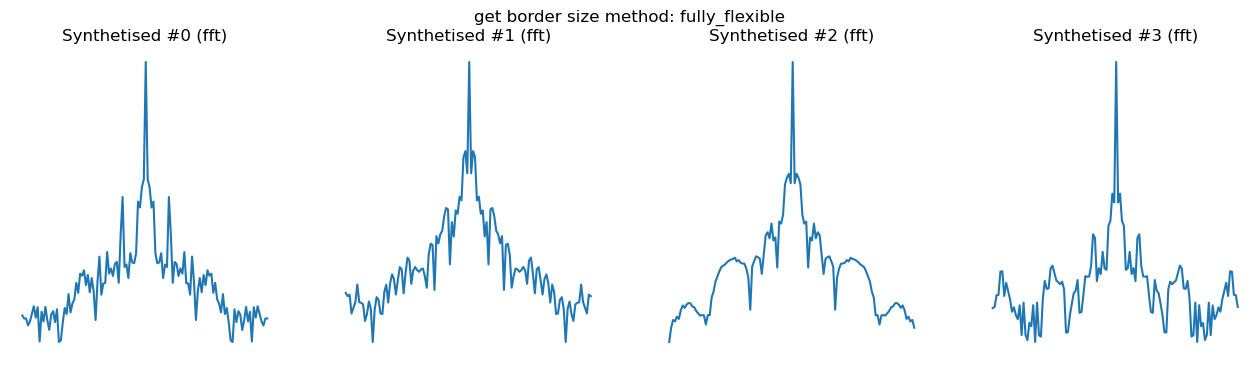

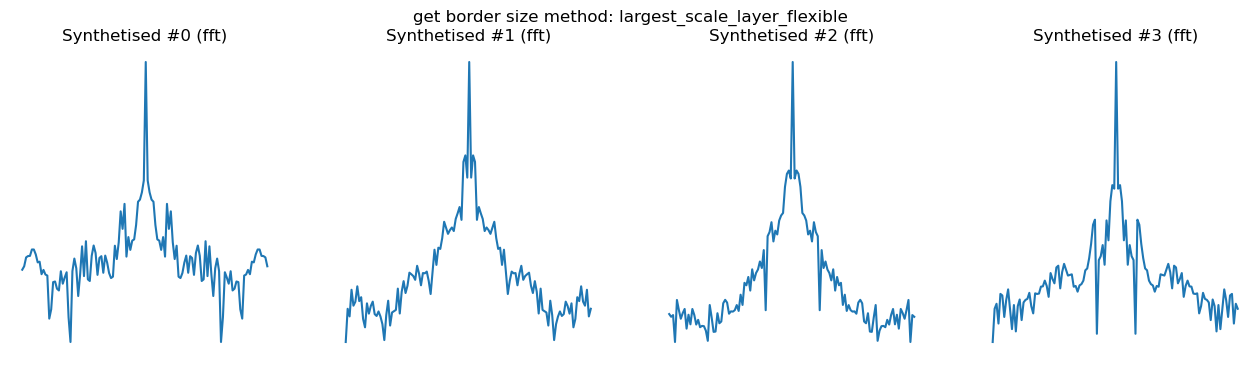

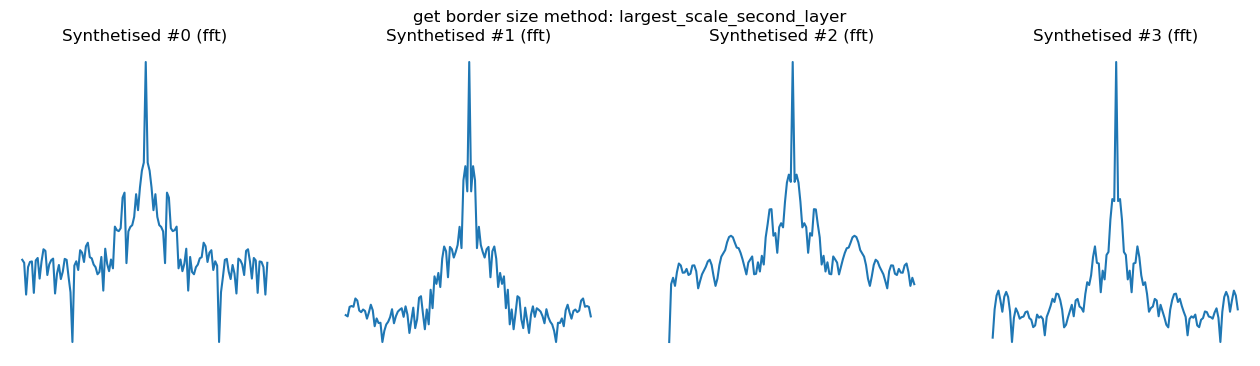

In [36]:
plt.figure(figsize=(10,10))
plt.subplot(2,2,1)
plt.plot(im[0,0,0,:128])
plt.axis('off')
plt.title('Target')
plt.subplot(2,2,2)
plt.semilogy(np.abs(np.fft.fftshift(np.fft.fft(im[0,0,0,:128]))))
plt.axis('off')
plt.title('Target (fft)')

for method_name, u in synthesis_target_npbc_results.items():
    plt.figure(figsize=(16,4))
    plt.title('get border size method: %s\n'%method_name)
    plt.axis('off')
    for k in range(4):
        plt.subplot(1,4,1+k)
        plt.semilogy(np.abs(np.fft.fftshift(np.fft.fft(u[k].cpu().numpy()))))
        plt.axis('off')
        plt.title('Synthetised #%d (fft)'%(k))

In [37]:
synthesis_target_running_npbc_results = {}

target = DataClass(im[0,0,0,:128], pbc=False)

for method_name, get_crop_border_size_method in zip(['fully_flexible', 
                                                     'largest_scale_layer_flexible', 
                                                     'largest_scale_second_layer'],
                                                    [WO._get_crop_border_size_fully_flexible,
                                                     WO._get_crop_border_size_largest_scale_layer_flexible,
                                                     WO._get_crop_border_size_largest_scale_second_layer]):
    print(method_name)
    J = 5 if method_name == 'fully_flexible' else 4

    st_op = target.get_ST_op(J=J, get_crop_border_size_method=get_crop_border_size_method)

    u = synthesize_from_maps(
            data_target=target,
            st_op_target_kwargs={"get_crop_border_size_method": get_crop_border_size_method},
            st_op_running_kwargs={"get_crop_border_size_method": get_crop_border_size_method},
            pbc_running=False,
            nbatch=4,
            max_iter=300,
            seed=seed,
        )

    synthesis_target_running_npbc_results[method_name] = u

fully_flexible
Running synthesis on device: mps:0 dtype: torch.float32
Initial shape for u: (4, 1, 128)
Prefiltering target to remove frequencies above Nyquist
Synthesis on 48 ST coefficients
Prefiltering initial map to remove frequencies above Nyquist
[LBFGS] iter 10, loss = 2.617455e+02
[LBFGS] iter 20, loss = 2.852836e+00
[LBFGS] iter 30, loss = 1.668735e+00
[LBFGS] iter 40, loss = 1.086511e+00
[LBFGS] iter 50, loss = 7.775937e-01
[LBFGS] iter 60, loss = 5.844772e-01
[LBFGS] iter 70, loss = 4.486297e-01
[LBFGS] iter 80, loss = 3.465051e-01
[LBFGS] iter 90, loss = 2.676595e-01
[LBFGS] iter 100, loss = 2.124004e-01
[LBFGS] iter 110, loss = 1.439252e-01
[LBFGS] iter 120, loss = 5.916173e-02
[LBFGS] iter 130, loss = 3.008939e-02
[LBFGS] iter 140, loss = 1.817967e-02
[LBFGS] iter 150, loss = 1.148874e-02
[LBFGS] iter 160, loss = 7.404141e-03
[LBFGS] iter 170, loss = 5.425824e-03
[LBFGS] iter 180, loss = 3.623949e-03
[LBFGS] iter 190, loss = 2.014839e-03
[LBFGS] iter 200, loss = 1.172479e

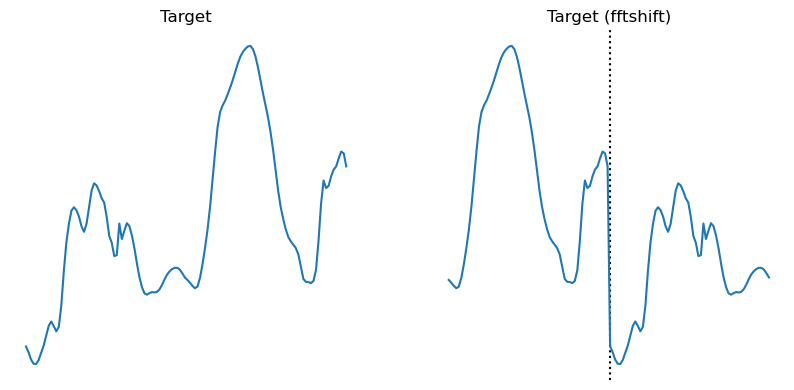

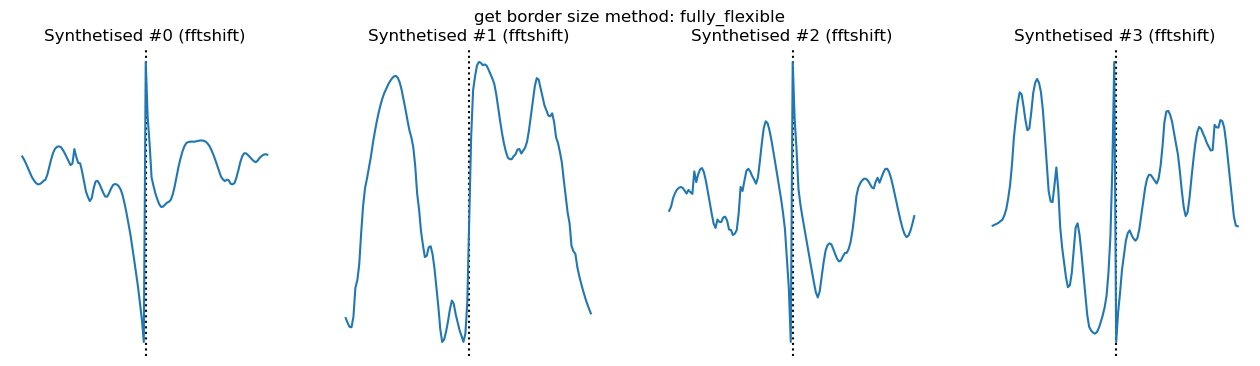

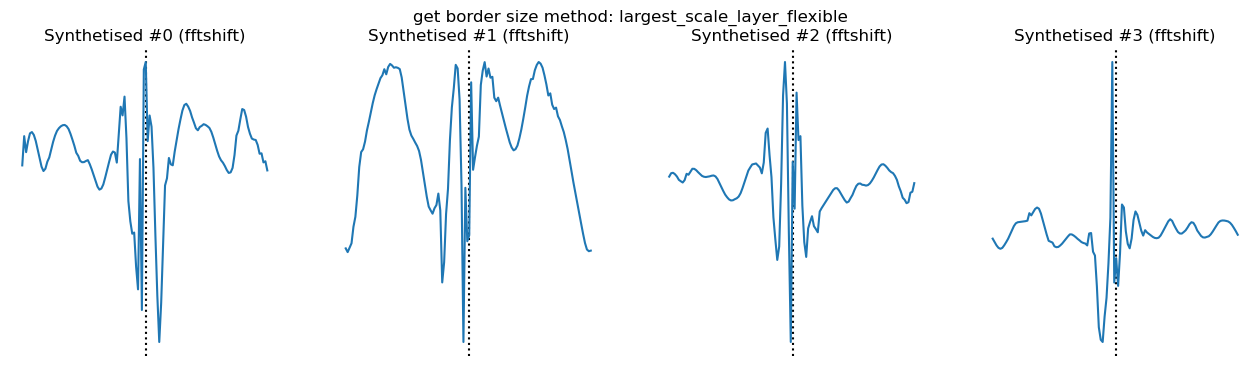

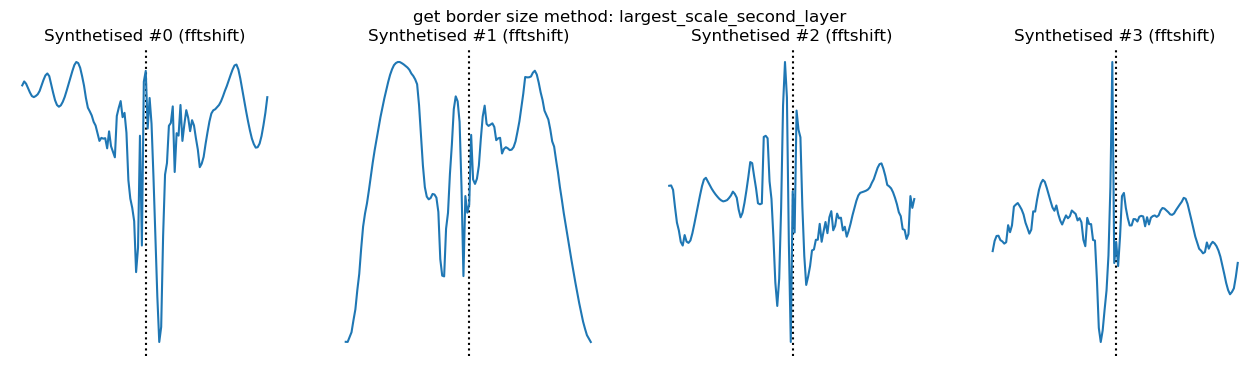

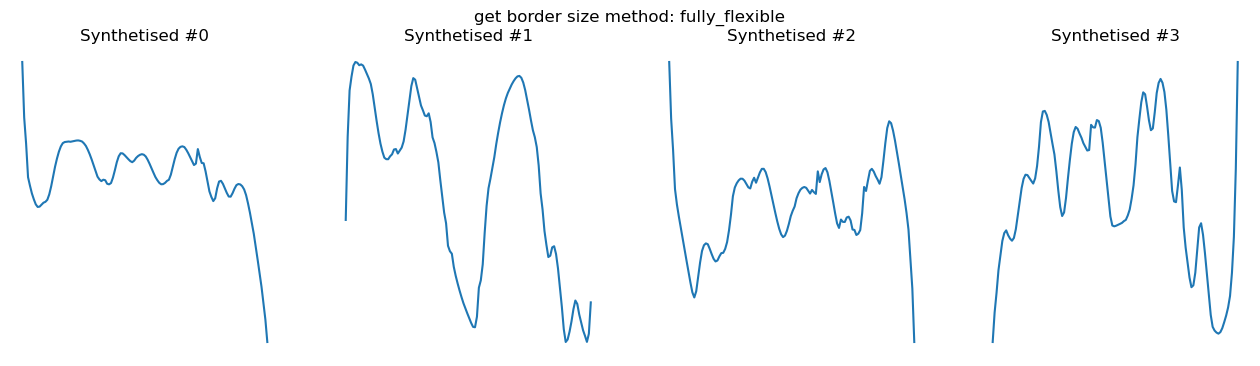

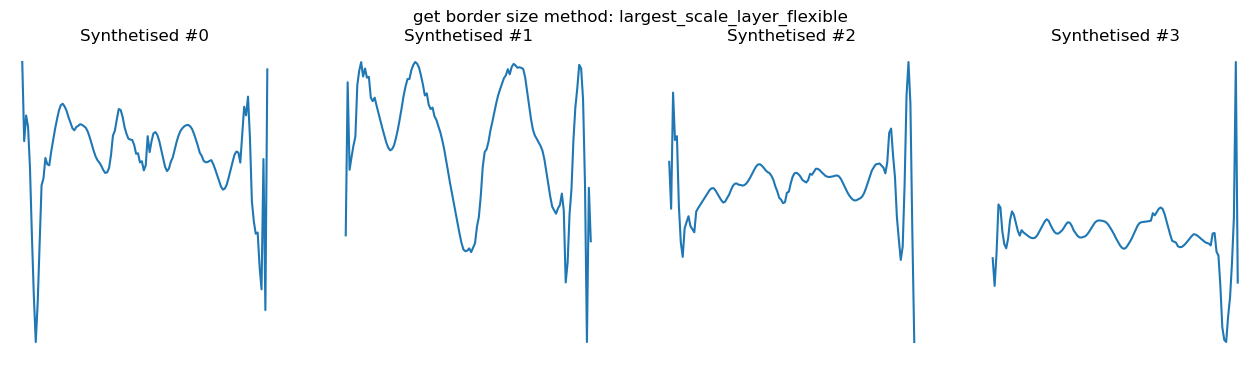

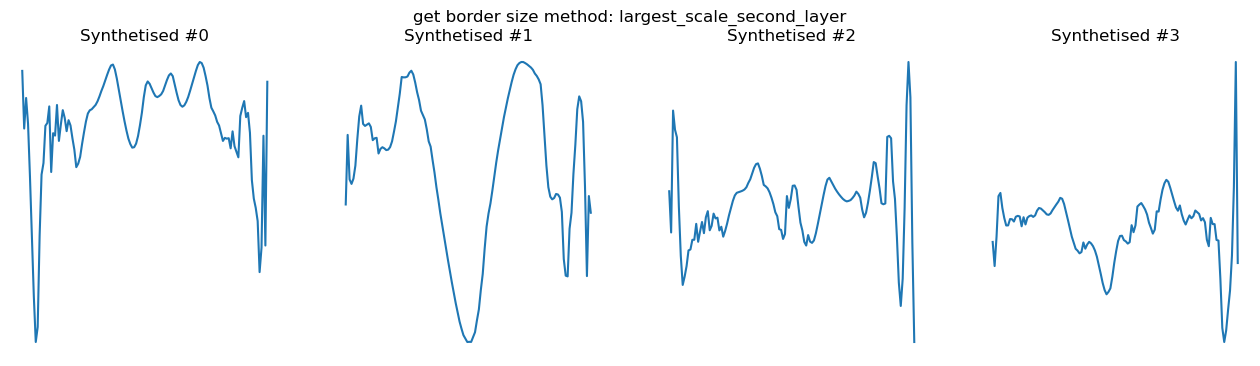

In [38]:
plt.figure(figsize=(10,10))
plt.subplot(2,2,1)
plt.plot(im[0,0,0,:128])
plt.axis('off')
plt.title('Target')
plt.subplot(2,2,2)
plt.axvline(64, color='black', linestyle=':')
plt.plot(np.fft.fftshift(im[0,0,0,:128]))
plt.axis('off')
plt.title('Target (fftshift)')

for method_name, u in synthesis_target_running_npbc_results.items():
    plt.figure(figsize=(16,4))
    plt.title('get border size method: %s\n'%method_name)
    plt.axis('off')
    for k in range(4):
        plt.subplot(1,4,1+k)
        plt.axvline(64, color='black', linestyle=':')
        plt.plot(np.fft.fftshift(u[k].cpu().numpy()))
        plt.axis('off')
        plt.title('Synthetised #%d (fftshift)'%(k))

for method_name, u in synthesis_target_running_npbc_results.items():
    plt.figure(figsize=(16,4))
    plt.title('get border size method: %s\n'%method_name)
    plt.axis('off')
    for k in range(4):
        plt.subplot(1,4,1+k)
        plt.plot(u[k].cpu().numpy())
        plt.axis('off')
        plt.title('Synthetised #%d'%(k))

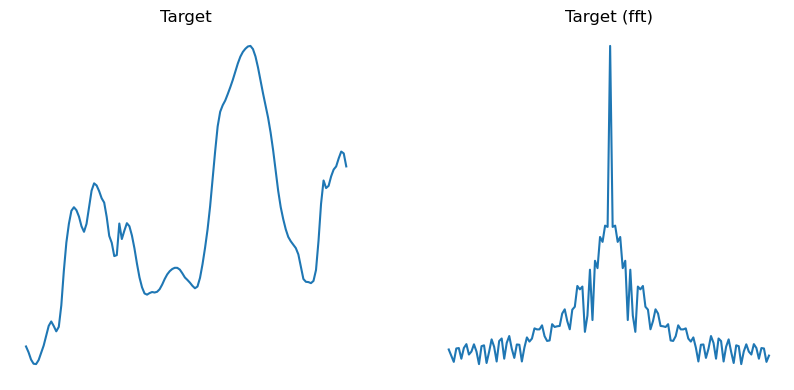

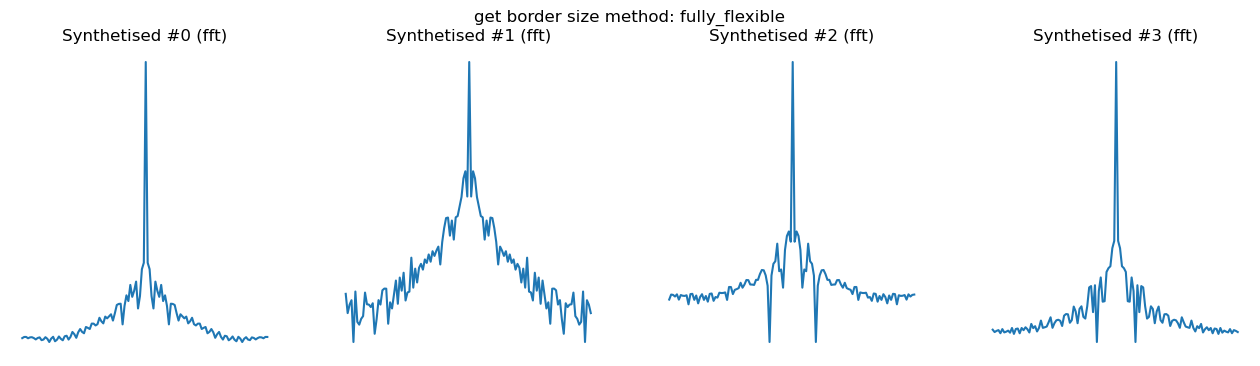

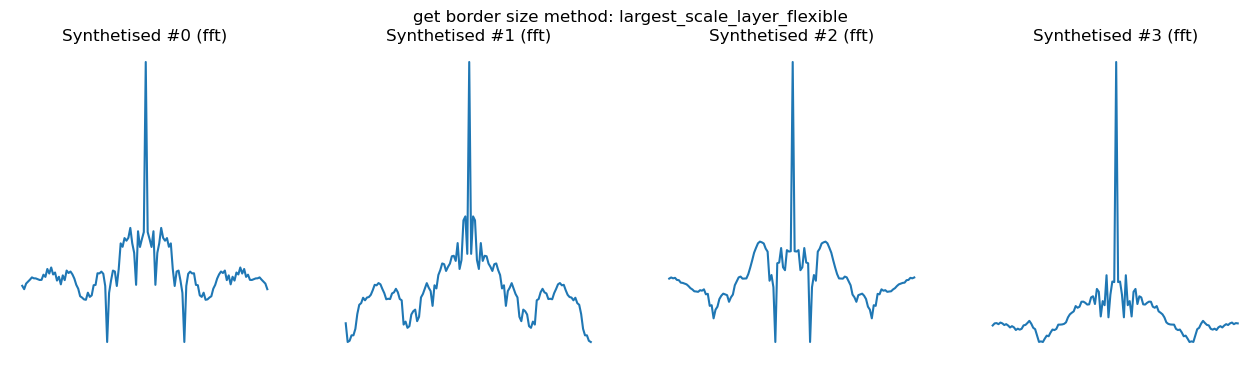

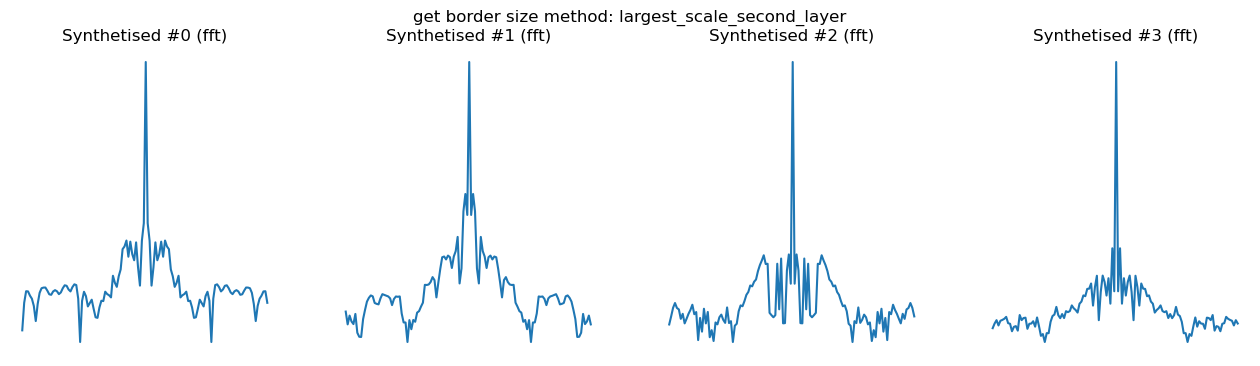

In [39]:
plt.figure(figsize=(10,10))
plt.subplot(2,2,1)
plt.plot(im[0,0,0,:128])
plt.axis('off')
plt.title('Target')
plt.subplot(2,2,2)
plt.semilogy(np.abs(np.fft.fftshift(np.fft.fft(im[0,0,0,:128]))))
plt.axis('off')
plt.title('Target (fft)')

for method_name, u in synthesis_target_running_npbc_results.items():
    plt.figure(figsize=(16,4))
    plt.title('get border size method: %s\n'%method_name)
    plt.axis('off')
    for k in range(4):
        plt.subplot(1,4,1+k)
        plt.semilogy(np.abs(np.fft.fftshift(np.fft.fft(u[k].cpu().numpy()))))
        plt.axis('off')
        plt.title('Synthetised #%d (fft)'%(k))

### Littlewood-Paley and energy conservation (1D)

The kernel wavelet transform never builds the wavelet at scale $j$ explicitly: the 5-tap kernel $K$ is applied to the signal downsampled $j$ times by the anti-aliasing kernel $H$. Seen from the original grid, the effective filter at scale $j$ is

$$\hat\psi_j(f) = \hat K(2^j f)\,\prod_{i<j}\hat H(2^i f).$$

For a stationary signal of power spectrum $P$, the expected second-order coefficients are $S_2(j) = \int P(f)\,|\hat\psi_j(f)|^2\,df$, whatever the subsampling. The Littlewood-Paley sum $LP(f) = \sum_j |\hat\psi_j(f)|^2$ therefore tells which frequencies the scattering statistics see:
- energy is conserved, $\sum_j S_2(j) = \mathrm{Var}(x)$, when $LP(f) = 1$ on the band covered by the scales ($|f| > 2^{-J}/2$, the lower frequencies being described by the mean and the power spectrum);
- where $LP(f) \approx 0$, the statistics do not constrain the energy: a synthesis started from white noise keeps its initial energy there, unless the power spectrum is added to the loss.

kernel taps: [-0.0303+0.1013j -0.12  -0.2043j  0.3005-0.j     -0.12  +0.2043j
 -0.0303-0.1013j]
LP sum, f > 0: min 0.233 at |f| = 0.500, mean 0.805, max 1.044
LP sum, f < 0: min 0.002 at |f| = 0.012, mean 0.089, max 0.228
energy fraction of each scale on negative frequencies: [0.038, 0.166, 0.16, 0.16, 0.161, 0.161]


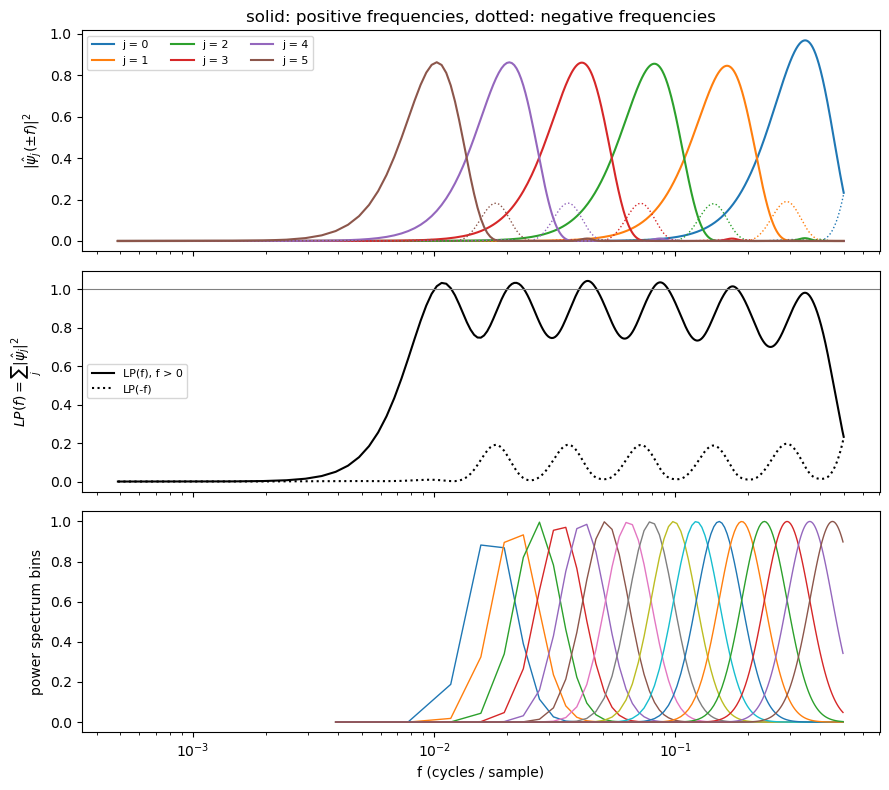

In [40]:
import torch

def effective_filters(w_op, N=2048):
    # |hat psi_j(f)| for j = 0..J-1 on the fftfreq grid of size N, from the kernels actually used by the operator
    K = w_op._wav_kernel[0, 0].detach().cpu().to(torch.complex128)
    H = w_op._get_smooth_kernel(device="cpu", dtype=torch.float64).to(torch.complex128)

    def dilated_fft(k, step):
        z = torch.zeros(N, dtype=torch.complex128)
        z[: len(k) * step : step] = k
        return torch.fft.fft(z)

    out, H_prod = [], torch.ones(N, dtype=torch.complex128)
    for j in range(w_op.J):
        out.append((dilated_fft(K, 2**j) * H_prod).abs())
        H_prod = H_prod * dilated_fft(H, 2**j)
    return torch.stack(out).numpy()  # [J, N]

lp_data = DataClass(im[0, 0, 0], pbc=True)
lp_w_op = lp_data.get_wavelet_op()
N_f = 2048
f = np.fft.fftfreq(N_f)
T = effective_filters(lp_w_op, N_f)
LP = (T**2).sum(0)
pos = f > 0
order = np.argsort(f[pos])
fp, Tp, LPp = f[pos][order], T[:, pos][:, order], LP[pos][order]
neg_index = (-np.arange(N_f)) % N_f            # index of -f
Tn, LPn = T[:, neg_index][:, pos][:, order], LP[neg_index][pos][order]   # values at -f, for f > 0

band = fp > 0.5 / 2**lp_w_op.J
print("kernel taps:", lp_w_op._wav_kernel[0, 0].cpu().numpy().round(4))
for name, L in [("f > 0", LPp), ("f < 0", LPn)]:
    i_min = np.argmin(L[band])
    print(f"LP sum, {name}: min {L[band].min():.3f} at |f| = {fp[band][i_min]:.3f}, mean {L[band].mean():.3f}, max {L[band].max():.3f}")
print("energy fraction of each scale on negative frequencies:",
      [round(float((T[j][f < 0] ** 2).sum() / (T[j] ** 2).sum()), 3) for j in range(lp_w_op.J)])

cs_op = lp_data.get_CS_op()
bins = cs_op.bin_masks.cpu().numpy()            # [n_bins, N] on the fftshifted grid of the signal
f_bins = np.fft.fftshift(np.fft.fftfreq(lp_data.array.shape[-1]))

fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
for j in range(lp_w_op.J):
    line, = axes[0].plot(fp, Tp[j] ** 2, label=f"j = {j}")
    axes[0].plot(fp, Tn[j] ** 2, color=line.get_color(), ls=":", lw=1)
axes[0].set_ylabel(r"$|\hat\psi_j(\pm f)|^2$")
axes[0].set_title("solid: positive frequencies, dotted: negative frequencies")
axes[0].legend(ncol=3, fontsize=8)
axes[1].plot(fp, LPp, color="k", label="LP(f), f > 0")
axes[1].plot(fp, LPn, color="k", ls=":", label="LP(-f)")
axes[1].axhline(1, color="gray", lw=0.8)
axes[1].legend(fontsize=8)
axes[1].set_ylabel(r"$LP(f)=\sum_j|\hat\psi_j|^2$")
for b in bins:
    axes[2].plot(f_bins[f_bins > 0], b[f_bins > 0], lw=1)
axes[2].set_ylabel("power spectrum bins")
axes[2].set_xlabel("f (cycles / sample)")
axes[2].set_xscale("log")
plt.tight_layout()
plt.show()

In [41]:
# Energy conservation: sum_j S2(j) / Var(x), measured with the ST operator and predicted from the LP sum.
def s2_energy_ratio(x):
    d = DataClass(x - x.mean(), pbc=True)
    st = d.get_ST_op(compute_PS=False).apply(d, norm="vanilla")
    s2 = st.S2.real.flatten().cpu().numpy()
    return s2.sum() / np.var(x)

rng = np.random.default_rng(0)
noise = rng.standard_normal(4096)
measured = s2_energy_ratio(noise)
predicted = LP.mean()  # white noise: flat spectrum
print(f"white noise : sum_j S2 / Var = {measured:.3f} (prediction from LP: {predicted:.3f})")
from STL_main.STL_2D_Kernel_Torch import STL_2D_Kernel_Torch
d2 = STL_2D_Kernel_Torch(rng.standard_normal((256, 256)), pbc=True)
st2 = d2.get_ST_op(compute_PS=False).apply(d2, norm="vanilla")
print(f"2D reference, white noise: sum_j,theta S2 / Var = {float(st2.S2.real.sum()) / float(d2.array.var()):.3f}")

x = im[0, 0, 0]
Px = np.abs(np.fft.fft(x - x.mean(), n=N_f)) ** 2
print(f"target row  : sum_j S2 / Var = {s2_energy_ratio(x):.3f} (prediction from LP: {(Px * LP).sum() / Px.sum():.3f})")

white noise : sum_j S2 / Var = 0.450 (prediction from LP: 0.441)
2D reference, white noise: sum_j,theta S2 / Var = 0.390
target row  : sum_j S2 / Var = 0.347 (prediction from LP: 0.370)


Running synthesis on device: mps:0 dtype: torch.float32
Initial shape for u: (4, 1, 256)
Prefiltering target to remove frequencies above Nyquist
Synthesis on 107 ST coefficients
Prefiltering initial map to remove frequencies above Nyquist
322 iterations of synthesis.
Execution time: 121.277 s
Running synthesis on device: mps:0 dtype: torch.float32
Initial shape for u: (4, 1, 256)
Prefiltering target to remove frequencies above Nyquist
Synthesis on 91 ST coefficients
Prefiltering initial map to remove frequencies above Nyquist
317 iterations of synthesis.
Execution time: 102.529 s
band          ratio with PS   ratio without PS   min LP in band
(0.00,0.05]           0.98               0.97            0.000
(0.05,0.10]           0.90               0.86            0.744
(0.10,0.20]           1.03               0.91            0.734
(0.20,0.30]           1.14               1.30            0.701
(0.30,0.38]           1.04               0.59            0.872
(0.38,0.45]           0.86        

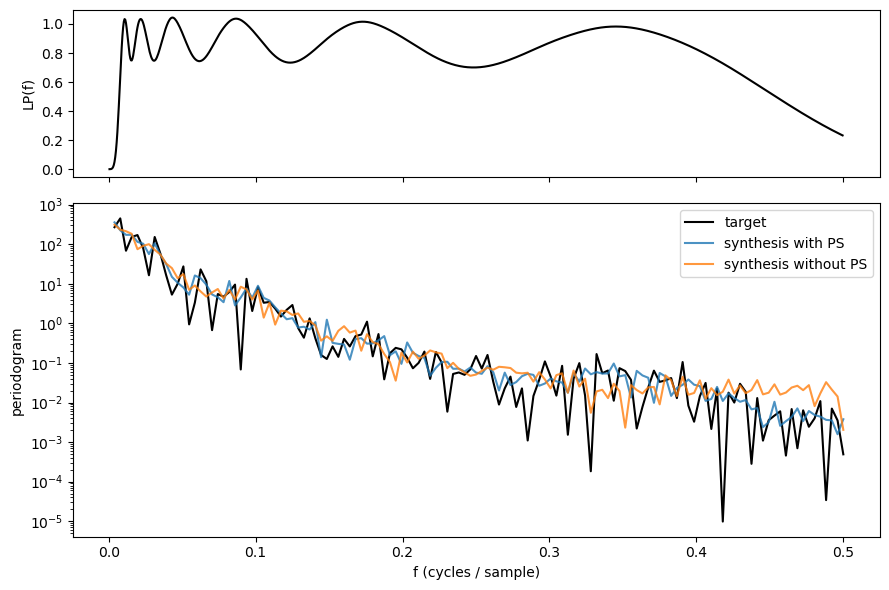

In [42]:
# Same synthesis as above, with and without the power spectrum in the loss
from STL_main.Synthesis import synthesize_from_maps
seed = 42
target_lp = DataClass(im[0, 0, 0], pbc=True)
u_ps = synthesize_from_maps(target_lp, pbc_running=True, nbatch=4, max_iter=300, seed=seed, verbose=False)
u_nops = synthesize_from_maps(target_lp, pbc_running=True, nbatch=4, max_iter=300, seed=seed, verbose=False, compute_PS=False)

def periodogram(a):
    a = np.atleast_2d(np.asarray(a))
    a = a - a.mean(-1, keepdims=True)
    return (np.abs(np.fft.rfft(a, axis=-1)) ** 2).mean(0)

x = im[0, 0, 0]
fr = np.fft.rfftfreq(len(x))
P_t, P_ps, P_nops = periodogram(x), periodogram(u_ps.cpu().numpy()), periodogram(u_nops.cpu().numpy())

print("band          ratio with PS   ratio without PS   min LP in band")
for lo, hi in [(0, 0.05), (0.05, 0.1), (0.1, 0.2), (0.2, 0.3), (0.3, 0.38), (0.38, 0.45), (0.45, 0.51)]:
    s = (fr > lo) & (fr <= hi)
    lp_min = LPp[(fp > lo) & (fp <= hi)].min()
    print(f"({lo:.2f},{hi:.2f}]   {P_ps[s].sum() / P_t[s].sum():12.2f}   {P_nops[s].sum() / P_t[s].sum():16.2f}   {lp_min:14.3f}")

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True, gridspec_kw={"height_ratios": [1, 2]})
axes[0].plot(fp, LPp, color="k")
axes[0].set_ylabel("LP(f)")
axes[1].semilogy(fr[1:], P_t[1:], label="target", color="k")
axes[1].semilogy(fr[1:], P_ps[1:], label="synthesis with PS", alpha=0.8)
axes[1].semilogy(fr[1:], P_nops[1:], label="synthesis without PS", alpha=0.8)
axes[1].set_xlabel("f (cycles / sample)")
axes[1].set_ylabel("periodogram")
axes[1].legend()
plt.tight_layout()
plt.show()

In [43]:
# Time reversal: with an analytic wavelet, x(-t) gives conjugated S3 and S4 (S1 and S2 unchanged),
# so Im S3 and Im S4 can detect time asymmetry. With an even (symmetric) wavelet they would be identical.
t = np.arange(1024)
y = (t % 37) / 37.0 + 0.3 * np.random.default_rng(1).standard_normal(1024)   # slow rise, sharp drop
op = DataClass(y, pbc=True).get_ST_op(compute_PS=False)
st_fwd = op.apply(DataClass(y, pbc=True), norm="vanilla")
st_bwd = op.apply(DataClass(y[::-1].copy(), pbc=True), norm="vanilla")
for k in ["S1", "S2", "S3", "S4"]:
    a, b = getattr(st_fwd, k), getattr(st_bwd, k)
    m = ~(a.isnan() | b.isnan())
    print(f"{k}: rel. diff = {float((a[m] - b[m]).abs().max() / a[m].abs().max()):.2e}, "
          f"rel. diff with conjugate = {float((a[m] - b[m].conj()).abs().max() / a[m].abs().max()):.2e}")

S1: rel. diff = 1.10e-07, rel. diff with conjugate = 1.10e-07
S2: rel. diff = 3.97e-08, rel. diff with conjugate = 3.97e-08
S3: rel. diff = 2.00e+00, rel. diff with conjugate = 1.59e-07
S4: rel. diff = 1.79e-01, rel. diff with conjugate = 1.74e-07


In [44]:
# The global amplitude c of the kernel is not neutral: after normalization by S2_ref,
# S1 and S2 are unchanged, but S3 scales as c and S4 as c^2, exactly like the ad hoc weights of the synthesis.
d = DataClass(im[0, 0, 0], pbc=True)
ref = {}
for c in (1.0, 2.0):
    op = d.get_ST_op(compute_PS=False)
    op.wavelet_op._wav_kernel = op.wavelet_op._wav_kernel * c
    st = op.apply(d.copy(), norm="store_ref")
    ref[c] = {k: getattr(st, k) for k in ["S1", "S2", "S3", "S4"]}
for k in ["S1", "S2", "S3", "S4"]:
    a, b = ref[1.0][k], ref[2.0][k]
    ok = ~(a.isnan() | b.isnan()) & (a.abs() > 0)
    print(f"{k}: median ratio (c=2 / c=1) = {(b[ok] / a[ok]).abs().median().item():.3f}")

S1: median ratio (c=2 / c=1) = 1.000
S2: median ratio (c=2 / c=1) = 1.000
S3: median ratio (c=2 / c=1) = 2.000
S4: median ratio (c=2 / c=1) = 4.000


**Reading of these results (1D wavelet = analytic 1D bump, $\hat\psi(f)$ built from `omega - xi0`, no amplitude factor)**

- **The wavelet is analytic.** The taps are complex, with a symmetric modulus: $[-0.030+0.101i,\ -0.120-0.204i,\ 0.300,\ \dots]$. Time reversal now conjugates $S_3$ and $S_4$ and leaves $S_1$ and $S_2$ unchanged; the relative difference with the conjugate is $2\cdot10^{-7}$. The imaginary parts of $S_3$ and $S_4$ can therefore detect time asymmetry. On the target, $\max|\mathrm{Im}\,S_3| \approx 0.12$ for $\max|S_3| \approx 0.17$, so these imaginary parts carry information.
- **Energy.** An analytic wavelet only sees the positive half of the spectrum of a real signal, so a tight analytic frame gives $\sum_j S_2 / \mathrm{Var} = 1/2$.
  - White noise gives 0.45, which is 90 % of that value. The target signal gives 0.35.
  - The 2D operator, whose wavelets are also one-sided, gives 0.39, so 1D and 2D are now on the same footing.
  - No amplitude factor is needed to keep the weights $3.5$ (S3) and $3.5^2$ (S4) consistent between 1D and 2D. Since $S_3 \propto c$ and $S_4 \propto c^2$ (last code cell), any factor would change those weights.
  - If the positive-frequency LP sum should average 1 instead, the factor is $1/\sqrt{0.805} \approx 1.11$.
- **Price of analyticity with 5 taps:**
  - The positive-frequency LP sum is between 0.70 and 1.04 (mean 0.81), against 0.92–1.05 for the even kernel.
  - The dips at the junctions between scales ($f \approx 0.25, 0.125, \dots$) come from the leakage of each scale $j \ge 1$ to negative frequencies (16 % of its energy, 4 % at $j = 0$). This leakage is caused by the aliasing of the anti-aliasing kernel $H$. It is visible as the dotted humps of the first plot, where the negative-frequency LP sum peaks at about 0.2.
  - Near Nyquist, the LP sum drops from 0.98 at $f \approx 0.35$ to 0.23 at $f = 1/2$, for two reasons. The bump, centered at Nyquist, is built on a grid that stops at Nyquist, so its upper half is truncated. A 5-tap analytic filter cannot separate $+f$ from $-f$ near $1/2$, where both are the same frequency.
- **Syntheses:**
  - Without the power spectrum, the excess in $(0.45, 0.5]$ is still about 4.8. It is now partly a coverage hole (LP sum 0.23 to 0.5) and partly a redistribution of energy within the finest octave: the ratio is 0.59 in $(0.30, 0.38]$ and 1.27 in $(0.38, 0.45]$.
  - With the power spectrum, the ratio is between 0.86 and 1.14 in every band, and 1.11 near Nyquist, better than with the even kernel (1.28).
- **Possible improvements, if the coverage near Nyquist or between scales matters:** a longer kernel (7–9 taps), or a sharper anti-aliasing kernel $H$. Both reduce the leakage to negative frequencies and fill the dips.
